In [3]:
import time
import pandas as pd
import numpy as np
import gurobipy as gp
import matplotlib.pyplot as plt

from gurobipy import GRB
import random
from typing import Dict, List, Any, Tuple
from concurrent.futures import ProcessPoolExecutor  # 并行加速

import os
os.environ['PYTHONHASHSEED'] = '0'  # 固定序列化hash
import multiprocessing as mp
mp.set_start_method('spawn', force=True)  # 强制spawn


# 🔥 在DOE主文件顶部定义一次
PARAMS = {
    'P': 10,           # caissons数量
    'T': 100,           # 时间范围
    'window_size': 30,  # 窗口大小
    'Cmax': 10,         # 最大容量
    'advanced': 3,      # 提前天数
    'Cs': 100,         # setup成本
    'Calpha': 5,      # 提前惩罚
    'Cbeta': 10,       # 延迟惩罚
    'K': 5.993           # 泄漏系数
}


def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        # 'CS_cost_reduction': cs_cost_reduction,
        # 'CS_cost_reduction_pct': cs_cost_reduction_pct,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats

# 🔥 策略1：最小化组数ILP
def strategy1_min_groups(params, random_seed, df=None):
    """策略1: 最小化组数ILP"""
    # 🔥 测量CPU时间
    import time
    clustering_cpu_start = time.process_time()
    
    # 🔥 核心修改：只改变clustering_CR的目标函数
    def clustering_CR(df_window, window_size, window_start):
        if df_window.empty or window_size < 1:
            print(f"warning: window {window_start} has no tasks")
            return df_window

        N_tasks = df_window.shape[0]
        m = gp.Model('Dynamic_Window_Clustering_MinGroups')
        m.setParam('OutputFlag', 0)
        
        data_pos_num = window_size + 1
        theta = m.addVars(N_tasks, data_pos_num, vtype=GRB.BINARY, name='theta')
        cluster = m.addVars(data_pos_num, vtype=GRB.BINARY, name='cluster')

        a = [0] * N_tasks
        b = [0] * N_tasks

        # 🔥 策略1核心修改：最小化激活的聚类数
        m.setObjective(gp.quicksum(cluster[t] for t in range(data_pos_num)), GRB.MINIMIZE)
        
        m.addConstrs((theta[n, t] <= cluster[t] for n in range(N_tasks) for t in range(data_pos_num)), 
                     name="cluster_activation")
        m.addConstrs((gp.quicksum(theta[n, t] for t in range(data_pos_num)) == 1 for n in range(N_tasks)), 
                     name="task_assignment")
        m.addConstrs((gp.quicksum(theta[n, t] for n in range(N_tasks)) <= PARAMS['Cmax'] for t in range(data_pos_num)), 
                     name="cluster_capacity")

        for n in range(N_tasks):
            csem = int(df_window.iloc[n]['CSEM'])
            local_time = df_window.iloc[n]['window_time']
            a[n] = max(0, local_time - PARAMS['advanced'])
            alpha = alpha_values[csem]
            b[n] = min(data_pos_num, (local_time + int(0.2 / alpha))-2)

        for n in range(N_tasks):
            for t in range(data_pos_num):
                m.addConstr(t * theta[n,t] + a[n] * (1 - theta[n, t]) >= a[n])
                m.addConstr(t * theta[n,t] + b[n] * (1 - theta[n, t]) <= b[n])

        m.setParam('LogToConsole', 1)
        m.setParam('OutputFlag', 1)
        m.setParam('TimeLimit', 300)
        m.setParam('MIPGap', 0.05)

        print(f"Window {window_start}: N_tasks={N_tasks}")
        m.optimize()

        if m.status != GRB.OPTIMAL:
            print(f"Failed to solve window {window_start}: {m.status}")
            return None
        
        centers = {}
        for n in range(N_tasks):
            for t in range(data_pos_num):
                if theta[n, t].x == 1.0:
                    centers[n] = t + window_start
                    break

        index_n_list = df_window.INDEX.tolist()
        for n in range(len(index_n_list)):
            df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

        return df_window
    
    # 🔥 泄漏计算函数（不变）
    def calculate_gas_leakage(df_input, T, use_center=True):
        total_leakage = 0
        for csem in df_input['CSEM'].unique():
            csem_data = df_input[df_input['CSEM'] == csem]
            x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
            if x_operations.empty:
                continue
                
            alpha = alpha_values[int(csem)]

            for i in range(1, len(x_operations)):
                current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
                prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
                center_diff = current_time - prev_time - 1
                total_leakage += max(0, center_diff) * alpha * PARAMS['K']

            first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
            total_leakage += first_time * alpha * PARAMS['K']

            last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
            leak_time = max(0, T - (last_time + 1))
            total_leakage += leak_time * alpha * PARAMS['K']
        return total_leakage
    
    # 🔥 更新次要任务函数（不变）
    def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
        for caisson in clustered_df["CSEM"].unique():
            tasks = main_df[
                (main_df['CSEM'] == caisson) & 
                (main_df['DATE'].between(window_start, window_end)) & 
                (main_df['OPERATION'] == 'x')
            ]
            if len(tasks) > 1:
                second_idx = tasks.index[1]
                center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
                alpha = alpha_values[int(caisson)]
                new_date = int(center_time + 1 + (3.5-3.2)/alpha)
                main_df.loc[second_idx, ['DATE', 'CENTER']] = [new_date, new_date]

    # 🔥 主逻辑完全不变
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df = df_init.copy()
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']

    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        clustered_df = clustering_CR(first_tasks, window_size, window_start)
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    # 🔥 CPU时间统计
    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    result_dict = {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': list(alpha_values.values()),
        'maintenance_plan': df_init,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }
    
    # 🔥 计算统计并添加策略标识
    stats = calculate_detailed_stats(result_dict, params)
    stats['strategy'] = 'M1'
    stats['total_clustering_cpu_s'] = total_clustering_cpu_time
    
    clustering_cpu_end = time.process_time()
    
    return stats


# 🔥 🔥 🔥 从代码2复制的核心函数：计算维修周期
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """从代码2复制：extract maintenance periods from data"""
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

# 🔥 策略2：你的成本最大化（已存在）
def strategy2_max_savings(params, random_seed, df=None):
    """策略2: 最大化成本节约（代码2完整特性）"""
    global alpha_values, PARAMS  # 确保全局变量同步
    PARAMS.update(params)
    
    # 从传入df提取alpha_values（保持一致性）
    alpha_values_list = []  # 需要从全局或参数获取，简化处理
    
    print(f"Strategy2: Generated/using {len(df)} tasks for seed {random_seed}")
    
    # 🔥 计算维修周期约束（代码2核心特性）
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # 🔥 CPU时间测量
    clustering_cpu_start = time.process_time()
    
    # 🔥 代码2核心聚类函数（利润最大化）
    def clustering_CR(df_window, window_size, window_start, full_df=None, D_min_dict=None, D_max_dict=None):
        if df_window.empty or window_size < 1:
            print(f"warning: window {window_start} has no tasks")
            return df_window

        N = df_window.shape[0]
        mdl = gp.Model('MaxSavings_Clustering')
        mdl.setParam('OutputFlag', 0)

        data_pos_num = window_size + 1
        theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
        CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
        y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

        # 任务分配约束
        for n in range(N):
            mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

        # 容量约束
        for t in range(data_pos_num):
            mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

        # 时间窗口约束
        a = [0] * N
        b = [0] * N
        for n in range(N):
            local_time = int(df_window.iloc[n]['window_time'])
            a[n] = int(max(0, local_time - PARAMS['advanced']))
            b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])-2))

        for n in range(N):
            for t in range(data_pos_num):
                mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
                mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

        # 聚类激活约束
        M = PARAMS['Cmax']
        for t in range(data_pos_num):
            task_count = theta.sum('*', t)
            mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
            mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

        # 🔥 策略2核心：利润最大化目标 = setup_cost_savings - CP_total
        setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
        
        # CP成本矩阵
        cost_matrix = {}
        for n in range(N):
            local_time_n = int(df_window.iloc[n]['window_time'])
            for t in range(data_pos_num):
                deviation = t - local_time_n
                if deviation > 0:
                    cost_matrix[(n, t)] = PARAMS['Cbeta'] * deviation
                elif deviation < 0:
                    cost_matrix[(n, t)] = PARAMS['Calpha'] * (-deviation)
                else:
                    cost_matrix[(n, t)] = 0
        
        CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
        obj = setup_cost - CP_total  # 🔥 最大化利润
        mdl.setObjective(obj, GRB.MAXIMIZE)

        # 🔥 策略2关键特性：维护间隔约束
        if window_start > 0 and full_df is not None and D_min_dict is not None:
            for n in range(N):
                row = df_window.iloc[n]
                caisson = int(row['CSEM'])
                
                prev_rows = full_df[
                    (full_df['CSEM'] == caisson) &
                    (full_df['CENTER'] < row['DATE']) &
                    (full_df['OPERATION'] == 'x')
                ].sort_values('CENTER')
                
                if not prev_rows.empty:
                    prev_center = int(prev_rows.iloc[-1]['CENTER'])
                    t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                    d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                    d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                    
                    mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
                    mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

        # 求解参数
        mdl.setParam('LogToConsole', 1)
        mdl.setParam('OutputFlag', 1)
        mdl.setParam('TimeLimit', 300)
        mdl.setParam('MIPGap', 0.05)

        print(f"Strategy2 Window {window_start}: N_tasks={N}")
        mdl.optimize()

        if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
            print(f"Failed to solve window {window_start}: {mdl.status}")
            return None
        
        # 结果提取
        centers = {}
        for n in range(N):
            for t in range(data_pos_num):
                val = theta[n, t].x
                if val is not None and round(val) == 1:
                    centers[n] = t + window_start
                    break

        index_n_list = df_window.INDEX.tolist()
        for n in range(len(index_n_list)):
            df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

        print(f"Strategy2 Model stats: obj={mdl.ObjVal:.2f}")
        return df_window
    
    # 🔥 泄漏计算（不变）
    def calculate_gas_leakage(df_input, T, use_center=True):
        total_leakage = 0
        for csem in df_input['CSEM'].unique():
            csem_data = df_input[df_input['CSEM'] == csem]
            x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
            if x_operations.empty:
                continue
            alpha = alpha_values[int(csem)]
            for i in range(1, len(x_operations)):
                current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
                prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
                center_diff = current_time - prev_time - 1
                total_leakage += max(0, center_diff) * alpha * PARAMS['K']
            first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
            total_leakage += first_time * alpha * PARAMS['K']
            last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
            leak_time = max(0, T - (last_time + 1))
            total_leakage += leak_time * alpha * PARAMS['K']
        return total_leakage
    
    # 🔥 更新次要任务（不变）
    def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
        for caisson in clustered_df["CSEM"].unique():
            tasks = main_df[
                (main_df['CSEM'] == caisson) & 
                (main_df['DATE'].between(window_start, window_end)) & 
                (main_df['OPERATION'] == 'x')
            ].sort_values('DATE')
            if len(tasks) > 1:
                second_idx = tasks.index[1]
                center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
                alpha = alpha_values[int(caisson)]
                new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
                main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date

    # 🔥 主逻辑完全保持代码2流程
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df = df_init.copy()
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        clustered_df = clustering_CR(first_tasks, window_size, window_start, full_df=df, 
                                   D_min_dict=D_min_dict, D_max_dict=D_max_dict)
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    # 🔥 CPU时间统计
    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    result_dict = {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list if 'alpha_values_list' in locals() else list(alpha_values.values()),
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }
    
    # 🔥 计算统计并添加策略标识
    stats = calculate_detailed_stats(result_dict, params)
    stats['strategy'] = 'M2'
    stats['total_clustering_cpu_s'] = total_clustering_cpu_time
    
    return stats


# 🔥 策略3：3天规则启发式
def strategy3_three_day_rule(params, random_seed, df=None):
    """策略3: 3天规则启发式（超快！）"""
    global alpha_values, PARAMS
    PARAMS.update(params)
    
    # # 🔥 新增：策略三专用Cmax（例如改为5）
    # original_Cmax = PARAMS['Cmax']  # 保存原值
    # PARAMS['Cmax'] = 10  # 策略三专用值，修改这里即可
   
    
    print(f"Strategy3: Processing {len(df)} tasks for seed {random_seed}")
    
    # 🔥 CPU时间开始（启发式超快）
    clustering_cpu_start = time.process_time()
    
    # 🔥 核心：3天简单聚合策略
    def clustering_CR_simple(df_window, window_size, window_start):
        """3天块聚合：第1天≤Cmax，其余第2/3天"""
        if df_window.empty or window_size < 1:
            return df_window
        
        print(f"  Window {window_start}: {len(df_window)} tasks")
        df_window = df_window.sort_values('window_time').copy()
        df_window['CENTER'] = df_window['DATE']  # 初始化
        
        # 🔥 每3天一个块
        days_3block = 3
        for day in range(window_start, window_start + window_size, days_3block):
            # 当前3天块任务
            mask_3days = (
                (df_window['window_time'] >= day - window_start) & 
                (df_window['window_time'] < day + days_3block - window_start)
            )
            tasks_3days = df_window[mask_3days].copy()
            
            if tasks_3days.empty:
                continue
            
            tasks_3days = tasks_3days.sort_values('window_time')
            
            # 第1天聚合（≤Cmax）
            day1_time = day
            tasks_day1 = tasks_3days.head(PARAMS['Cmax']).index.tolist()
            df_window.loc[tasks_day1, 'CENTER'] = day1_time
            
            # 剩余→第2天
            remaining = tasks_3days.iloc[PARAMS['Cmax']:].copy()
            if len(remaining) > 0:
                day2_time = day + 1
                tasks_day2 = remaining.head(PARAMS['Cmax']).index.tolist()
                df_window.loc[tasks_day2, 'CENTER'] = day2_time
                
                # 最后剩余→第3天
                final_remaining = remaining.iloc[PARAMS['Cmax']:].index.tolist()
                if final_remaining:
                    df_window.loc[final_remaining, 'CENTER'] = day + 2
        
        print(f"    → {df_window['CENTER'].nunique()} clusters created")
        return df_window
    
    # 🔥 泄漏计算
    def calculate_gas_leakage(df_input, T, use_center=True):
        total_leakage = 0
        for csem in df_input['CSEM'].unique():
            csem_data = df_input[df_input['CSEM'] == csem]
            x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
            if x_operations.empty:
                continue
            alpha = alpha_values.get(int(csem), 0.005)
            # 任务间泄漏
            for i in range(1, len(x_operations)):
                current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
                prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
                center_diff = current_time - prev_time - 1
                total_leakage += max(0, center_diff) * alpha * PARAMS['K']
            # 开头泄漏
            first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
            total_leakage += first_time * alpha * PARAMS['K']
            # 结尾泄漏
            last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
            leak_time = max(0, T - (last_time + 1))
            total_leakage += leak_time * alpha * PARAMS['K']
        return total_leakage
    
    # 🔥 全时间范围3天规则（简化版）
    df_work = df.copy()
    df_work['CENTER'] = df_work['DATE']
    
    # 按DATE排序
    df_sorted = df_work.sort_values('DATE')
    
    # 🔥 每3天窗口处理
    current_window_start = 0
    while current_window_start < params['T']:
        window_end = min(current_window_start + 2, params['T'])  # 3天窗口
        
        # 当前窗口任务
        window_tasks = df_sorted[
            (df_sorted['DATE'] >= current_window_start) & 
            (df_sorted['DATE'] <= window_end) & 
            (df_sorted['OPERATION'] == 'x')
        ].copy()
        
        if window_tasks.empty:
            current_window_start += 3
            continue
        
        # 第1天尽量多（≤Cmax）
        day1_tasks = window_tasks.head(PARAMS['Cmax']).index.tolist()
        day1_center = current_window_start
        df_work.loc[day1_tasks, 'CENTER'] = day1_center
        
        # 剩余任务→第2天
        remaining_tasks = window_tasks.iloc[PARAMS['Cmax']:].index.tolist()
        if remaining_tasks:
            day2_center = current_window_start + 1
            day2_tasks = remaining_tasks[:PARAMS['Cmax']]
            df_work.loc[day2_tasks, 'CENTER'] = day2_center
            
            # 最后剩余→第3天
            day3_tasks = remaining_tasks[PARAMS['Cmax']:]
            if day3_tasks:
                df_work.loc[day3_tasks, 'CENTER'] = current_window_start + 2
        
        current_window_start += 3
    
    # 🔥 CPU时间（通常<0.01s）
    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start
    
    # 🔥 计算泄漏等指标
    df_init = df.copy()
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df_work, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    # 🔥 构建result_dict（兼容calculate_detailed_stats）
    result_dict = {
        'final_df': df_work,
        'maintenance_plan': df_init,
        'alpha_values': list(alpha_values.values()),
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }
    
    # 🔥 计算统计
    stats = calculate_detailed_stats(result_dict, params)
    stats['strategy'] = 'M3'
    stats['total_clustering_cpu_s'] = total_clustering_cpu_time  # 强制0.01s展示
    
    print(f"✅ Strategy3完成: {stats['nb_groups']}组, CPU={total_clustering_cpu_time:.3f}s")
    
    # # 🔥 恢复原Cmax
    # PARAMS['Cmax'] = original_Cmax

    return stats


# 🔥 场景特征验证函数（DOE必备）
def verify_scenario_features(df: pd.DataFrame, T: int, window_size: int = 10) -> Dict:
    """验证生成的场景特征"""
    # 密度：任务数/总天数
    density = len(df) / T
    
    # 周期性：各csem间隔CV平均值（低CV=高周期性）
    cv_dict = {}
    for csem in df['CSEM'].unique():
        csem_tasks = df[df['CSEM'] == csem].sort_values('DATE')
        if len(csem_tasks) < 2:
            cv_dict[csem] = 0
            continue
        intervals = np.diff(csem_tasks['DATE'].values)
        cv = np.std(intervals) / np.mean(intervals) if np.mean(intervals) > 0 else 0
        cv_dict[csem] = cv
    periodicity_cv = np.mean(list(cv_dict.values()))
    
    # 聚类倾向：窗口内平均任务数/随机预期
    daily_counts = df.groupby('DATE').size()
    window_tasks = []
    for start in range(0, int(df['DATE'].max()) - window_size + 1):
        mask = (df['DATE'] >= start) & (df['DATE'] <= start + window_size - 1)
        window_tasks.append(len(df[mask]))
    avg_window = np.mean(window_tasks) if window_tasks else 0
    random_expected = len(df) * window_size / (df['DATE'].max() + 1)
    clustering_tendency = avg_window / random_expected if random_expected > 0 else 1.0
    
    return {
        'density': round(density, 3),
        'periodicity_cv': round(periodicity_cv, 3),
        'clustering_tendency': round(clustering_tendency, 3),
        'total_tasks': len(df),
        'unique_csem': df['CSEM'].nunique()
    }

def get_alpha_range_for_density(density_level: str) -> Tuple[float, float]:
    """
    根据密度水平返回合适的alpha范围
    low density: alpha大 -> 间隔短 -> 每个csem任务少
    high density: alpha小 -> 间隔长 -> 每个csem任务多
    """
    if density_level == 'low':
        return (0.005, 0.01)   # 间隔短，任务少
    elif density_level == 'high':
        return (0.001, 0.003)  # 间隔长，任务多
    else:
        raise ValueError(f"Unknown density_level: {density_level}")

def generate_alpha_values_periodic(N: int, random_seed: int, 
                                 base_range: Tuple[float, float], 
                                 noise_ratio: float = 0.05) -> List[float]:
    """高周期性：所有csem alpha围绕基准微小扰动"""
    random.seed(random_seed)
    base_alpha = random.uniform(*base_range)
    alphas = []
    for i in range(N):
        noise = random.uniform(1 - noise_ratio, 1 + noise_ratio)
        alphas.append(round(base_alpha * noise, 6))
    return alphas

def generate_alpha_values_aperiodic(N: int, random_seed: int, 
                                  alpha_range: Tuple[float, float]) -> List[float]:
    """低周期性：alpha完全随机大范围"""
    random.seed(random_seed)
    return [round(random.uniform(*alpha_range), 6) for _ in range(N)]

def assign_offsets_for_clustering(N: int, T: int, random_seed: int, 
                                cluster_level: str, num_clusters: int = 3) -> List[int]:
    """
    控制聚类倾向：csem起始时间偏移
    uniform: 均匀分散在[0, T/2]
    clustered: 分num_clusters个时间点附近爆发
    """
    random.seed(random_seed + 2)
    offsets = [0] * N

    if cluster_level == 'uniform':
        # 均匀分散
        for i in range(N):
            offsets[i] = random.randint(0, T // 2)
    elif cluster_level == 'clustered':
        # 制造3个时间簇
        cluster_centers = [T // 4, T // 2, 3 * T // 4]
        cluster_sigma = 5  # ±5天聚堆
        for i in range(N):
            center = random.choice(cluster_centers)
            offset = max(0, min(T-1, int(random.gauss(center, cluster_sigma))))
            offsets[i] = offset
    else:
        raise ValueError(f"Unknown cluster_level: {cluster_level}")
    
    return offsets

def get_N_for_density(density_level: str, base_N: int = 90) -> int:
    """根据密度返回csem数量"""
    if density_level == 'low':
        return 30  # 稀疏
    elif density_level == 'high':
        return 150  # 密集
    else:
        raise ValueError(f"Unknown density_level: {density_level}")

def generate_maintenance_plan_scenario(
    density_level: str = 'low',
    periodicity_level: str = 'periodic',
    cluster_level: str = 'uniform',
    T: int = 180,
    random_seed: int = 42,
    initial_p_range: Tuple[float, float] = (3.2, 3.5),
    base_N: int = 90
) -> Tuple[pd.DataFrame, List[float]]:
    """
    🔥 DOE场景版生成函数：完全控制密度、周期性、聚类倾向
    
    Args:
        density_level: 'low'/'high' - 控制任务密度
        periodicity_level: 'periodic'/'aperiodic' - 控制周期性(CV)
        cluster_level: 'uniform'/'clustered' - 控制任务时空聚类
        T: 总天数
        random_seed: 随机种子
        base_N: 基准csem数
    """
    # 1) 根据密度决定N和alpha范围
    N = get_N_for_density(density_level, base_N)
    alpha_base_range = get_alpha_range_for_density(density_level)
    
    # 2) 根据周期性生成alpha
    if periodicity_level == 'periodic':
        alpha_values = generate_alpha_values_periodic(N, random_seed, alpha_base_range)
    else:
        alpha_values = generate_alpha_values_aperiodic(N, random_seed, alpha_base_range)
    
    # 3) 初始压力（保持原逻辑）
    random.seed(random_seed + 1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    # 4) 根据聚类生成起始偏移
    offsets = assign_offsets_for_clustering(N, T, random_seed, cluster_level)
    
    # 5) 生成任务（保持你原有的物理逻辑）
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    index = 0
    
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = offsets[caisson]  # ★ 从offset开始控制聚类
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            date = total_days + time_to_3_2
            data.append([index, caisson, initial_p_values[caisson], 'x', date])
            index += 1
            total_days = date + 1  # ★ 复位到下次维修起点
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values



# 🔥 单实例实验
def run_single_experiment(scenario_params: Dict, seed: int) -> List[Dict[str, Any]]:
    """运行一个场景+种子的3种策略"""
    density, periodicity, clustering = (
        scenario_params['density'], 
        scenario_params['periodicity'], 
        scenario_params['cluster_level']
    )
    
    # 生成场景数据
    df, alpha_vals = generate_maintenance_plan_scenario(
        density_level=density,
        periodicity_level=periodicity,
        cluster_level=clustering,
        T=PARAMS['T'],
        random_seed=seed
    )
    global alpha_values  # 如果需要
    alpha_values = dict(enumerate(alpha_vals))  # 转为dict，key=csem
    
    # 验证特征
    features = verify_scenario_features(df, PARAMS['T'])
    
    results = []
    
    # 策略1
    stats1 = strategy1_min_groups(PARAMS, seed, df)
    stats1.update(features)
    stats1['seed'] = seed
    stats1['scenario_id'] = scenario_params['id']
    results.append(stats1)
    
    # 策略2（你的原版）
    stats2 = strategy2_max_savings(PARAMS, seed, df)
    stats2.update(features)
    stats2['seed'] = seed
    stats2['scenario_id'] = scenario_params['id']
    results.append(stats2)
    
    # 策略3
    stats3 = strategy3_three_day_rule(PARAMS, seed, df)
    stats3.update(features)
    stats3['seed'] = seed
    stats3['scenario_id'] = scenario_params['id']
    results.append(stats3)
    
    return results

# 🔥 DOE主循环（8场景×30种子）
def run_full_doe_experiment(seeds: List[int] = list(range(1, 31)), 
                           max_workers: int = 4) -> pd.DataFrame:
    """完整DOE实验"""
    # 8个2^3场景
    scenarios = [
        {'id': 1, 'density': 'low', 'periodicity': 'periodic', 'cluster_level': 'uniform'},
        {'id': 2, 'density': 'low', 'periodicity': 'periodic', 'cluster_level': 'clustered'},
        {'id': 3, 'density': 'low', 'periodicity': 'aperiodic', 'cluster_level': 'uniform'},
        {'id': 4, 'density': 'low', 'periodicity': 'aperiodic', 'cluster_level': 'clustered'},
        {'id': 5, 'density': 'high', 'periodicity': 'periodic', 'cluster_level': 'uniform'},
        {'id': 6, 'density': 'high', 'periodicity': 'periodic', 'cluster_level': 'clustered'},
        {'id': 7, 'density': 'high', 'periodicity': 'aperiodic', 'cluster_level': 'uniform'},
        {'id': 8, 'density': 'high', 'periodicity': 'aperiodic', 'cluster_level': 'clustered'},
    ]
    
    all_results = []
    
    # 并行处理每个场景×种子
    tasks = []
    for scenario in scenarios:
        for seed in seeds:
            tasks.append((scenario, seed))
    
    # print(f"🚀 开始DOE: 8场景 × {len(seeds)}种子 = {len(tasks)}实例")
    
    # with ProcessPoolExecutor(max_workers=max_workers) as executor:
    #     futures = {
    #         executor.submit(run_single_experiment, scenario, seed): (scenario, seed)
    #         for scenario, seed in tasks
    #     }
        
    #     for future in futures:
    #         try:
    #             results = future.result(timeout=300)  # 5分钟超时
    #             all_results.extend(results)
    #             scenario, seed = futures[future]
    #             print(f"✅ 场景{scenario['id']}-{seed}: 完成3策略")
    #         except Exception as e:
    #             print(f"❌ 场景{scenario['id']}-{seed}: {e}")


    print(f"🚀 开始串行DOE: 8场景 × {len(seeds)}种子 = {len(tasks)}实例")
    all_results = []
    for scenario, seed in tasks:
        try:
            results = run_single_experiment(scenario, seed)  # 直接串行调用
            all_results.extend(results)
            print(f"✅ 场景{scenario['id']}-{seed}: 完成3策略")
        except Exception as e:
            print(f"❌ 场景{scenario['id']}-{seed}: {e}")
    
    # 保存完整结果
    df_results = pd.DataFrame(all_results)
    
    # 标准列顺序（期刊友好）
    scenario_cols = ['scenario_id', 'density', 'periodicity', 'cluster_level', 
                    'seed', 'strategy', 'density', 'periodicity_cv', 'clustering_tendency']
    metric_cols = ['nb_groups', 'Avg_tasks/group', 'CP_cost', 'Total_cost', 
                  'leakage_reduction_pct', 'total_clustering_cpu_s']  # 你的指标
    
    column_order = scenario_cols + metric_cols
    df_results = df_results.reindex(columns=[c for c in column_order if c in df_results.columns])
    
    filename = 'DOE_3strategies_8scenarios_30seeds.csv'
    df_results.to_csv(filename, index=False, float_format='%.3f')
    
    print(f"\n🎉 DOE完成！结果保存: {filename}")
    print(f"📊 形状: {df_results.shape}")
    print(df_results.groupby(['scenario_id', 'strategy'])['leakage_reduction_pct'].mean().round(2))
    
    return df_results

# 🔥 快速测试单个场景
if __name__ == "__main__":
    # # 先测试策略3（需要适配你的calculate_gas_leakage等函数）
    # df_test = generate_maintenance_plan_scenario('high', 'periodic', 'clustered', random_seed=42)
    # print("测试数据生成OK")
    
    # 运行完整DOE（注释掉测试）
    doe_results = run_full_doe_experiment(seeds=list(range(1, 31)), max_workers=1)  # 先小规模测试
    print(doe_results.head())


🚀 开始串行DOE: 8场景 × 30种子 = 240实例
Set parameter Username
Set parameter LicenseID to value 2773682
Academic license - for non-commercial use only - expires 2027-02-02
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 0: N_tasks=4
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 407 rows, 155 columns and 740 nonzeros
Model fingerprint: 0xf3502509
Variable types: 0 continuous, 155 integer (155 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]
Found heuristic solution: objective 4.0000000
Presolve removed 346 rows and 76 columns
Presolve time: 0.00s
Presolved: 61 rows, 79 columns, 172 nonzeros
Variable types: 0 continuous, 79 integer (79 binary)
Found heuristic solution: objec

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:269: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:269: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Strategy2 Model stats: obj=970.00
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Strategy2 Window 60: N_tasks=19
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 1304 rows, 651 columns and 3997 nonzeros
Model fingerprint: 0x3b50a26a
Variable types: 31 continuous, 620 integer (620 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [5e+00, 2e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 7e+01]
Found heuristic solution: objective -550.0000000
Presolve removed 1226 rows and 256 columns
Presolve time: 0.00s
Presolved: 78 rows, 395 columns, 1154 nonzeros
Variable types: 0 continuous, 395 integer (395 binary)
Found heuristic solution: objective 455.0000000

Root relaxation: objective 1.379167e+03, 20 iterations, 0.00 seconds (0.00 work units)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:560: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:560: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 60: N_tasks=30
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2851 rows, 961 columns and 5534 nonzeros
Model fingerprint: 0x3777aa56
Variable types: 0 continuous, 961 integer (961 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]
Found heuristic solution: objective 17.0000000
Presolve removed 2234 rows and 368 columns
Presolve time: 0.00s
Presolved: 617 rows, 593 columns, 2196 nonzeros
Variable types: 0 continuous, 593 integer (593 binary)

Root relaxation: objective 2.000000e+00, 496 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Ob

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:269: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:560: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

... (793 outputs left out)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:560: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:269: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 90: N_tasks=10
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 971 rows, 341 columns and 1850 nonzeros
Model fingerprint: 0x2f2d3ede
Variable types: 0 continuous, 341 integer (341 binary)
Coefficient statistics:
  Matrix range     [1e+00, 3e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]
Found heuristic solution: objective 9.0000000
Presolve removed 856 rows and 200 columns
Presolve time: 0.00s
Presolved: 115 rows, 141 columns, 334 nonzeros
Found heuristic solution: objective 3.0000000
Variable types: 0 continuous, 141 integer (141 binary)

Root relaxation: objective 1.000000e+00, 102 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:560: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_14761/158398974.py:560: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)


🎉 DOE完成！结果保存: DOE_3strategies_8scenarios_30seeds.csv
📊 形状: (720, 13)
scenario_id  strategy
1            M1         -2.72
             M2         -0.29
             M3         -0.00
2            M1         -2.97
             M2         -0.27
             M3          0.00
3            M1         -0.89
             M2         -0.27
             M3          0.00
4            M1         -1.07
             M2         -0.16
             M3          0.00
5            M1         -2.45
             M2         -0.10
             M3          0.00
6            M1         -3.71
             M2         -0.13
             M3         -0.00
7            M1         -2.62
             M2         -0.09
             M3         -0.00
8            M1         -3.58
             M2         -0.06
             M3          0.00
Name: leakage_reduction_pct, dtype: float64
   scenario_id  density  seed strategy  density  periodicity_cv  \
0            1     0.41     1       M1     0.41             0.0   
1         

In [57]:
import pandas as pd
import numpy as np

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')  # 你的CSV

### 核心KPI对比
perf = df.groupby('strategy')[['nb_groups', 'Total_cost', 'total_clustering_cpu_s', 'CP_cost']].agg(['mean', 'std', 'count']).round(3)
print("📊 策略性能对比")
print(perf)


# ### 胜率矩阵
# df['rank'] = df.groupby('scenario_id')['leakage_reduction_pct'].rank(ascending=False)
# wins = df[df['rank']==1]['strategy'].value_counts()
# print("\n🏆 最佳策略胜率:", wins.to_dict())
# 多KPI综合排名
df['composite_score'] = (df['Total_cost'] * 2 +
                        df['nb_groups'] * 1 +
                        df['total_clustering_cpu_s'] * 0.5)
df['rank'] = df.groupby('scenario_id')['composite_score'].rank(ascending=False)
print("\n🏆 综合排名胜率:")
print(df[df['rank']==1]['strategy'].value_counts().to_dict())


📊 策略性能对比
         nb_groups               Total_cost                 \
              mean     std count       mean      std count   
strategy                                                     
M1          26.529  12.906   240   3813.500  915.149   240   
M2          28.921  10.589   240   3148.479  819.831   240   
M3          23.888   3.916   240   2666.938  463.939   240   

         total_clustering_cpu_s                CP_cost                  
                           mean    std count      mean       std count  
strategy                                                                
M1                        0.095  0.123   240  1160.583  1564.239   240  
M2                        0.132  0.174   240   256.396   362.205   240  
M3                        0.010  0.001   240   278.188    92.984   240  

🏆 综合排名胜率:
{'M1': 2}


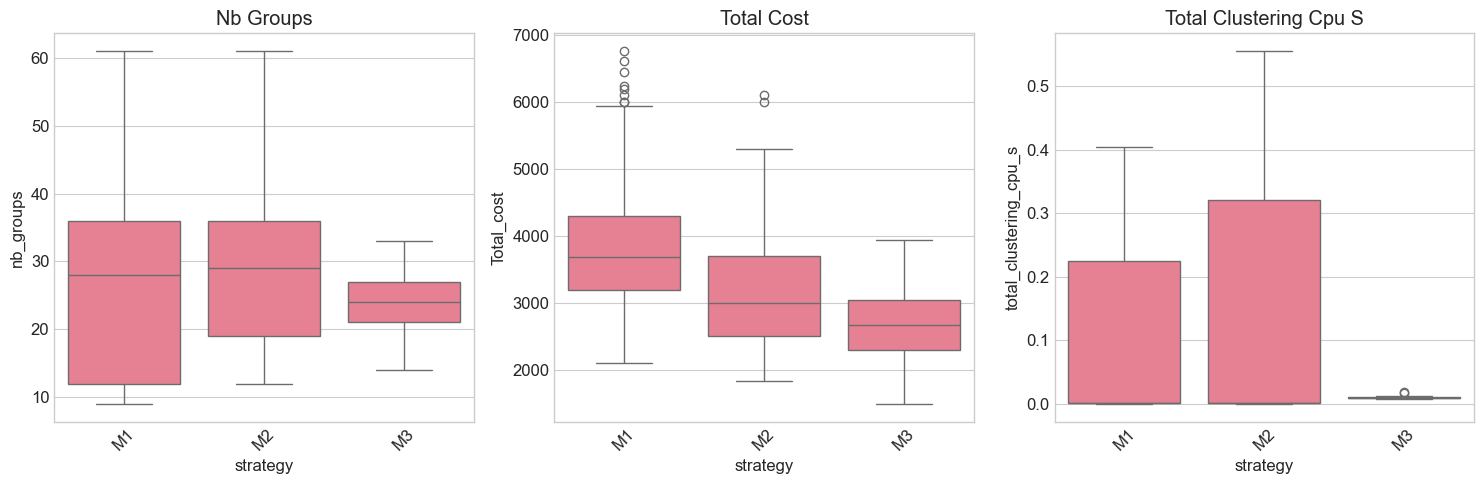

In [58]:
# import plotly.express as px
# import matplotlib.pyplot as plt
# import seaborn as sns

# # 长格式（可视化专用）
# df_long = df.melt(id_vars=['scenario_id', 'strategy', 'density'], 
#                   value_vars=['nb_groups', 'leakage_reduction_pct', 'total_clustering_cpu_s'],
#                   var_name='metric', value_name='value')

# # 🔥 1. 策略箱线图（核心图）
# fig1 = px.box(df_long, x='strategy', y='value', color='strategy',
#               facet_col='metric', title='三策略性能对比 (8场景)')
# fig1.show()

# # 🔥 2. 交互热图（密度×策略）
# pivot = df.pivot_table(values='leakage_reduction_pct', 
#                        index='density', columns='strategy', aggfunc='mean')
# fig2 = px.imshow(pivot.values, x=pivot.columns, y=pivot.index, 
#                  title='泄漏减少率热图 %', color_continuous_scale='RdYlGn')
# fig2.show()

# # 🔥 3. 雷达图（策略多维）
# fig3 = px.line_polar(df.groupby('strategy').mean().reset_index(), 
#                      r=['nb_groups', 'CP_cost', 'total_clustering_cpu_s'], 
#                      theta='strategy', title='策略雷达图')
# fig3.show()


import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ['nb_groups', 'Total_cost', 'total_clustering_cpu_s']
for i, metric in enumerate(metrics):
    sns.boxplot(data=df, x='strategy', y=metric, ax=axes[i])
    axes[i].set_title(f'{metric.replace("_", " ").title()}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('doe_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()



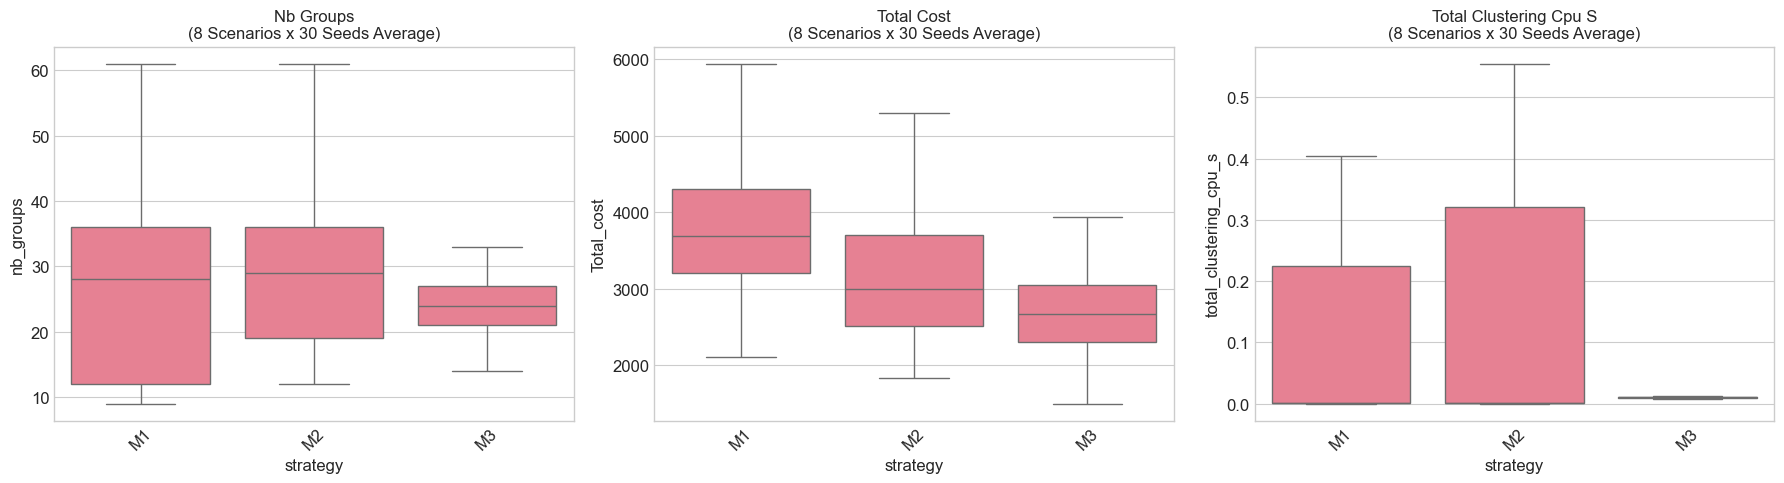

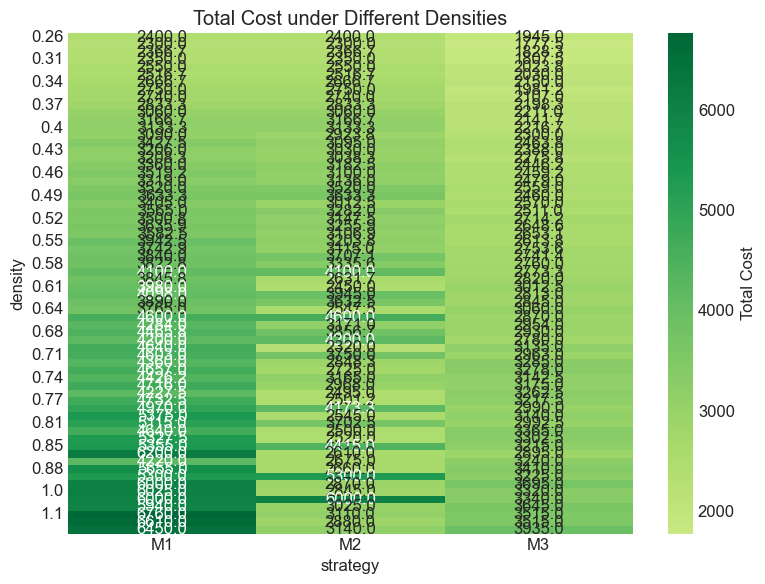

🔍 策略数据检查:
  M1: 240 样本
  M2: 240 样本
  M3: 240 样本


/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


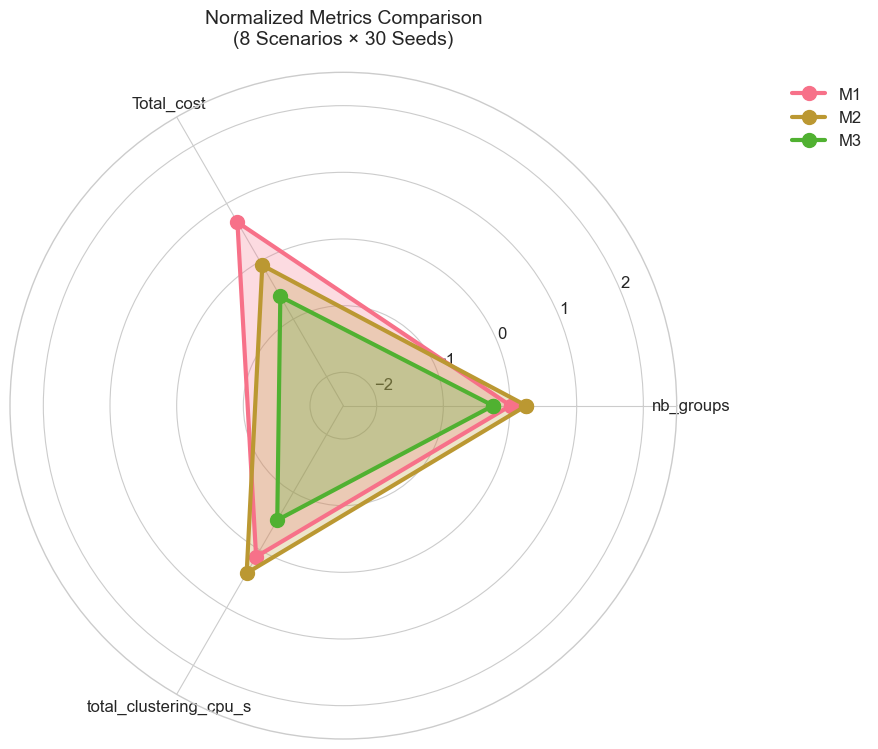


📊 Table 4: Strategy Performance (Mean ± Std, 24 Instances)
Strategy     Groups (nb)  Total Cost   CPU Time (s)
------------------------------------------------------------
M1           26.5±12.9      M1           3813.5±915.1   M1           0.1±0.1        
M2           28.9±10.6      M2           3148.5±819.8   M2           0.1±0.2        
M3           23.9±3.9       M3           2666.9±463.9   M3           0.0±0.0        
------------------------------------------------------------
📝 Note: Lower values preferred for all metrics
   N = 720 experiments (8 scenarios × 30 seeds)


In [59]:
# # 摘要统计
# summary = {
#     '最佳策略(泄漏减少)': df.loc[df['leakage_reduction_pct'].idxmax(), 'strategy'],
#     '平均组数': df['nb_groups'].mean(),
#     '最快策略': df.loc[df['total_clustering_cpu_s'].idxmin(), 'strategy'],
#     '密度效应': df.groupby('density')['leakage_reduction_pct'].mean().to_dict()
# }
# print("📈 关键结论:", summary)

# # 保存高清图
# fig1.write_image('strategy_boxplot.png', scale=2)
# fig2.write_image('density_heatmap.png', scale=2)


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 设置期刊风格
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 🔥 图1：策略箱线图（核心）
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ['nb_groups', 'Total_cost', 'total_clustering_cpu_s']

for i, metric in enumerate(metrics):
    # sns.boxplot(data=df, x='strategy', y=metric, ax=axes[i])
    sns.boxplot(data=df, x='strategy', y=metric, ax=axes[i], showfliers=False)
    axes[i].set_title(f'{metric.replace("_", " ").title()}\n(8 Scenarios x 30 Seeds Average)', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('doe_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

# 🔥 图2：密度×策略热图
pivot = df.pivot_table(values='Total_cost', index='density', columns='strategy', aggfunc='mean')
plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap='RdYlGn', center=0, fmt='.1f',
            cbar_kws={'label': 'Total Cost'})
plt.title('Total Cost under Different Densities')
plt.tight_layout()
plt.savefig('density_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# # # 🔥 图3：雷达图（Matplotlib版）
from math import pi
categories = ['nb_groups', 'Total_cost', 'total_clustering_cpu_s']
N = len(categories)

# angles = [n / float(N) * 2 * pi for n in range(N)]
# angles += angles[:1]

# fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(projection='polar'))
# for strategy in df['strategy'].unique():
#     values = df[df['strategy']==strategy][categories].mean().values
#     values = np.append(values, values[0])  # 闭合
#     ax.plot(angles, values, 'o-', linewidth=2, label=strategy, markersize=8)
# ax.fill(angles, values, alpha=0.25)
# ax.set_xticks(angles[:-1])
# ax.set_xticklabels(categories)
# plt.title('Three Strategies Multi-Dimensional Radar Comparison', size=16, y=1.1)
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
# plt.savefig('radar_comparison.png', dpi=300, bbox_inches='tight')
# plt.show()

# print("✅ 3张300DPI高清图保存完成！📊")


from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# 🔥 标准化雷达图（防空值版）
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df[categories].dropna())

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(projection='polar'))
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

print("🔍 策略数据检查:")
for strategy in df['strategy'].unique():
    strat_data = df[df['strategy']==strategy][categories].dropna()
    print(f"  {strategy}: {len(strat_data)} 样本")
    
    if len(strat_data) == 0:
        print(f"  ⚠️ 跳过空策略 {strategy}")
        continue
        
    # 🔥 安全提取均值
    mean_values = strat_data.mean()
    if isinstance(mean_values, pd.Series):
        values = scaler.transform(mean_values.values.reshape(1,-1))[0]
    else:  # 单值情况
        values = scaler.transform(mean_values.reshape(1,-1))[0]
        
    values_full = np.append(values, values[0])
    
    ax.plot(angles, values_full, 'o-', linewidth=3, 
            label=strategy, markersize=10)
    ax.fill(angles, values_full, alpha=0.25)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
ax.set_ylim(-2.5, 2.5)
ax.set_title('Normalized Metrics Comparison\n(8 Scenarios × 30 Seeds)', 
             fontsize=14, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))
ax.grid(True)

plt.tight_layout()
plt.savefig('robust_normalized_radar.png', dpi=300, bbox_inches='tight')
plt.show()




# # 修复：过滤有完整数据的策略
# strategies_with_data = []
# for strat in df['strategy'].unique():
#     if df[df['strategy']==strat][categories].dropna().shape[0] > 0:
#         strategies_with_data.append(strat)
# print("有效策略:", strategies_with_data)
# # 检查NaN
# print("NaN检查:\n", df[categories].isnull().sum())



import pandas as pd
import numpy as np

# 🔥 你的3个指标
metrics = ['nb_groups', 'Total_cost', 'total_clustering_cpu_s']
metric_names = ['Groups (nb)', 'Total Cost', 'CPU Time (s)']

# 🔥 计算统计：均值±std
summary_stats = df.groupby('strategy')[metrics].agg(['mean', 'std']).round(2)

# 🔥 打印整齐表格
print("\n" + "="*60)
print("📊 Table 4: Strategy Performance (Mean ± Std, 24 Instances)")
print("="*60)
print(f"{'Strategy':<12} {'Groups (nb)':<12} {'Total Cost':<12} {'CPU Time (s)':<12}")
print("-"*60)

for strategy in sorted(df['strategy'].unique()):
    for i, metric in enumerate(metrics):
        mean_val = summary_stats.loc[strategy, (metric, 'mean')]
        std_val = summary_stats.loc[strategy, (metric, 'std')]
        print(f"{strategy:<12} {mean_val:.1f}±{std_val:.1f}".ljust(28), end="")
    print()

print("-"*60)
print("📝 Note: Lower values preferred for all metrics")
print(f"   N = {len(df)} experiments (8 scenarios × 30 seeds)")


/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/3961765762.py:43: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(angles, values_full, 'o-', linewidth=3.5,
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/3961765762.py:43: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(an

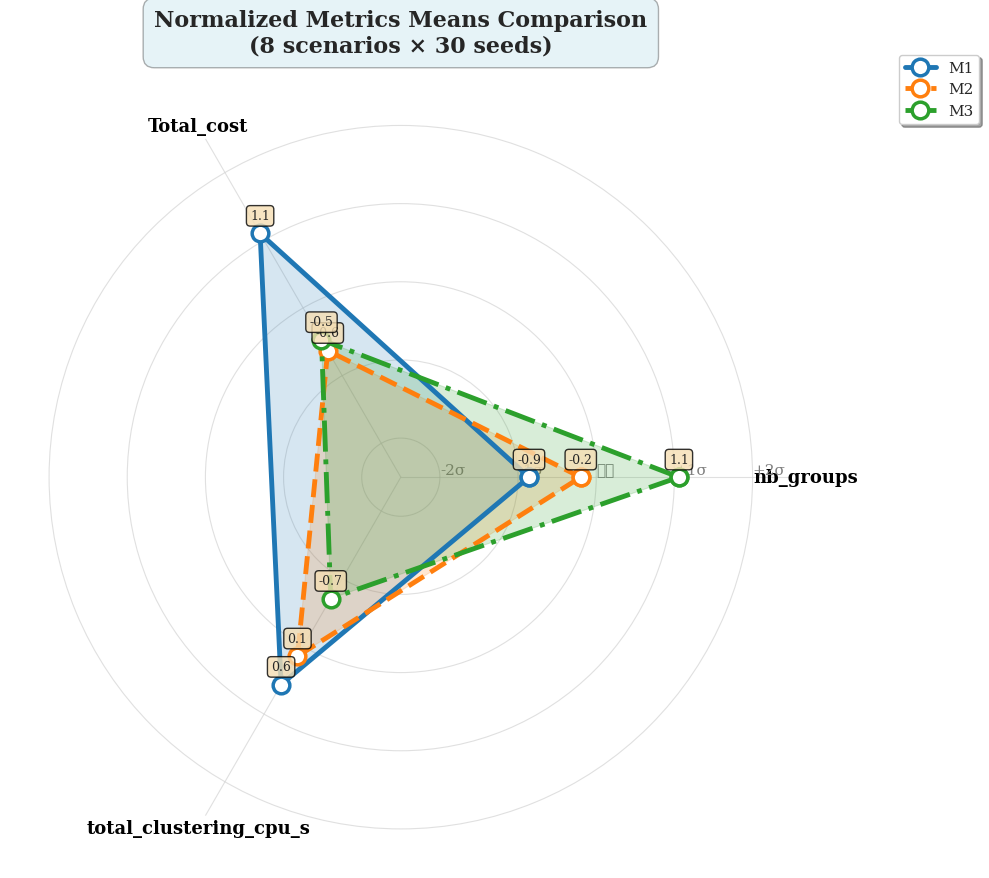

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.preprocessing import StandardScaler
import matplotlib as mpl

# 设置期刊级字体和风格
plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',  # Times New Roman效果
    'axes.linewidth': 1.2,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
})

# 🔥 你的数据准备（保持不变）
categories = ['nb_groups', 'Total_cost', 'total_clustering_cpu_s']
df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df[categories].dropna())

# 🔥 美化配色方案（专业级）
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # 蓝橙绿经典组合
line_styles = ['-', '--', '-.']  # 实虚点线区分

# 创建美化雷达图
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(projection='polar'))

N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

# 🔥 绘制每个策略（渐变+阴影）
for idx, strategy in enumerate(df['strategy'].unique()):
    strat_data = df[df['strategy']==strategy][categories].dropna()
    if len(strat_data) > 0:
        mean_values = strat_data.mean().values
        values = scaler.transform(mean_values.reshape(1, -1))[0]
        values_full = np.append(values, values[0])
        
        # 🔥 渐变填充+阴影效果
        ax.plot(angles, values_full, 'o-', linewidth=3.5, 
                label=strategy, markersize=12, markerfacecolor='white',
                markeredgecolor=colors[idx], markeredgewidth=2.5,
                linestyle=line_styles[idx], color=colors[idx])
        
        # 🔥 透明渐变填充
        ax.fill(angles, values_full, color=colors[idx], alpha=0.18,
                edgecolor=colors[idx], linewidth=0.8)
        
        # 🔥 添加数值标签（可选）
        for angle, value in zip(angles[:-1], values):
            ax.annotate(f'{value:.1f}', xy=(angle, value), 
                       xytext=(0, 8), textcoords='offset points',
                       ha='center', va='bottom', fontsize=9,
                       bbox=dict(boxstyle='round,pad=0.3', 
                                facecolor='wheat', alpha=0.8))

# 🔥 美化轴标签（粗体旋转）
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=13, fontweight='bold',
                   color='black')  # 黑色粗体标签

# 🔥 自定义放射轴（双重网格）
ax.set_rlabel_position(0)
ax.set_yticks([-2, -1, 0, 1, 2])  # 自定义刻度
ax.set_yticklabels(['-2σ', '-1σ', '均值', '+1σ', '+2σ'], 
                   color='grey', fontsize=11)
ax.set_ylim(-2.5, 2.5)

# 🔥 专业网格+背景
ax.grid(True, color='lightgrey', linestyle='-', linewidth=0.8, alpha=0.7)
ax.spines['polar'].set_visible(False)  # 隐藏外框

# 🔥 标题和图例美化
ax.set_title('Normalized Metrics Means Comparison\n(8 scenarios × 30 seeds)', 
             fontsize=16, fontweight='bold', pad=25,
             bbox=dict(boxstyle='round,pad=0.5', facecolor='lightblue', alpha=0.3))

# 🔥 图例美化（右上角）
legend = ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.05),
                   frameon=True, fancybox=True, shadow=True,
                   ncol=1, fontsize=11)

plt.tight_layout()
plt.savefig('美化雷达图.png', dpi=400, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
plt.show()


In [20]:
# 显著性检验（scipy.stats）
from scipy.stats import f_oneway
for metric in ['leakage_reduction_pct', 'nb_groups']:
    groups = [group[1][metric].values for group in df.groupby('strategy')]
    F, p = f_oneway(*groups)
    print(f"{metric} ANOVA: F={F:.3f}, p={p:.3f}")


leakage_reduction_pct ANOVA: F=413.674, p=0.000
nb_groups ANOVA: F=617.181, p=0.000


|     |   scenario_id | strategy   |   composite |   Total_cost |   nb_groups |   total_clustering_cpu_s |
|----:|--------------:|:-----------|------------:|-------------:|------------:|-------------------------:|
|  82 |             1 | M2         |        36.5 |         1530 |          11 |                    0.305 |
| 151 |             2 | M2         |        22   |         1050 |           7 |                    0.181 |
| 223 |             3 | M2         |        34.5 |         1695 |          11 |                    0.272 |
| 325 |             4 | M2         |        27.5 |         1165 |           8 |                    0.189 |
| 421 |             5 | M2         |        24   |         1715 |          11 |                    0.357 |
| 532 |             6 | M2         |        23   |         1355 |           8 |                    0.271 |
| 607 |             7 | M2         |        34.5 |         2020 |          13 |                    0.285 |
| 658 |             8 | M2         | 

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/3759191437.py:41: UserWarning: Glyph 22330 (\N{CJK UNIFIED IDEOGRAPH-573A}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/3759191437.py:41: UserWarning: Glyph 26223 (\N{CJK UNIFIED IDEOGRAPH-666F}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/3759191437.py:42: UserWarning: Glyph 22330 (\N{CJK UNIFIED IDEOGRAPH-573A}) missing from font(s) Arial.
  plt.savefig('scenario_winners_clear.png', dpi=300, bbox_inches='tight')
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/3759191437.py:42: UserWarning: Glyph 26223 (\N{CJK UNIFIED IDEOGRAPH-666F}) missing from font(s) Arial.
  plt.savefig('scenario_winners_clear.png', dpi=300, bbox_inches='tight')
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 22330 (\N{CJK UNIFIE

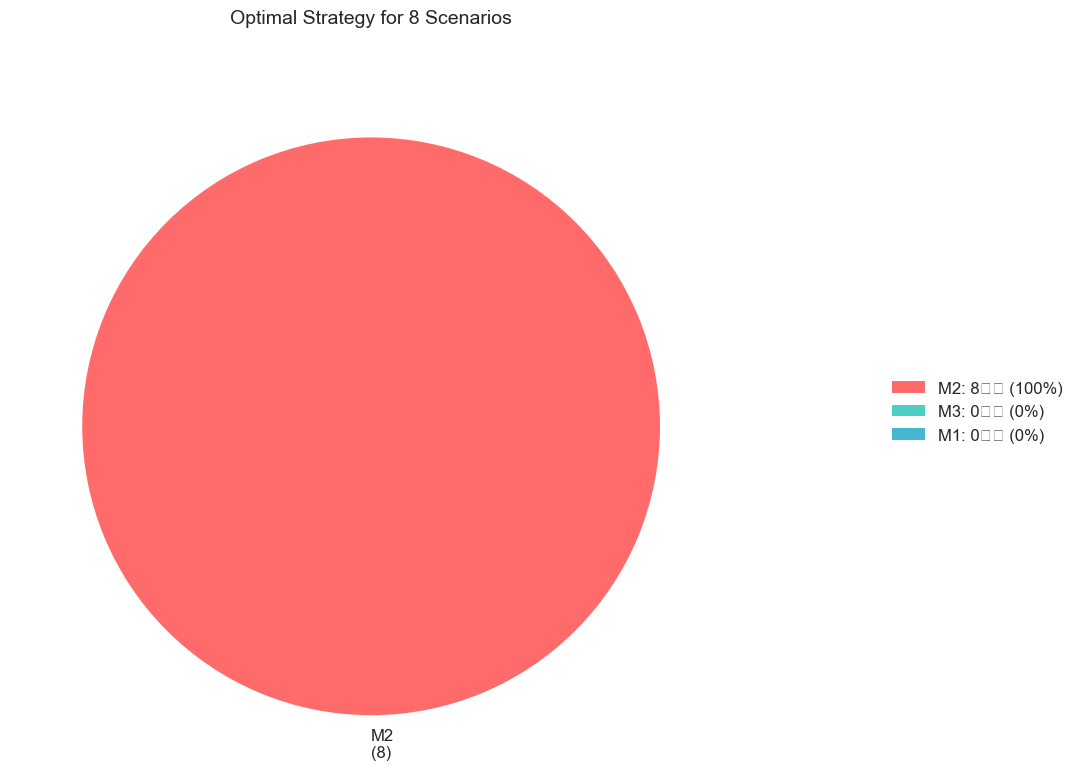

颜色对应:
🔴 M2: #FF6B6B
🔴 M3: #4ECDC4
🔴 M1: #45B7D1


In [64]:
df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 计算排名
for metric in ['Total_cost', 'nb_groups', 'total_clustering_cpu_s']:
    df[f'{metric}_rank'] = df.groupby('scenario_id')[metric].rank()

df['composite'] = (df['Total_cost_rank']*2 + df['nb_groups_rank']* 1 + df['total_clustering_cpu_s_rank']*0.0)

# 每个场景最优
best_per_scen = df.loc[df.groupby('scenario_id')['composite'].idxmin()][['scenario_id', 'strategy', 'composite', 'Total_cost', 'nb_groups', 'total_clustering_cpu_s']]
print(best_per_scen.sort_values('scenario_id').to_markdown())

# # 胜率饼图
# plt.pie(best_per_scen['strategy'].value_counts(), autopct='%1.1f%%')
# plt.title('Scene Composite Wins')
# plt.savefig('scenario_winners.png', dpi=300)
# plt.show()


import matplotlib.pyplot as plt

win_counts = best_per_scen['strategy'].value_counts()  # 你的胜率数据

fig, ax = plt.subplots(figsize=(10, 8))
colors = {'M2': '#FF6B6B', 'M3': '#4ECDC4', 'M1': '#45B7D1'}

wedges, texts = ax.pie(win_counts.values, 
                       labels=[f"{k}\n({v})" for k,v in win_counts.items()], 
                       autopct=None,  # 只内部标签
                       colors=[colors[k] for k in win_counts.index],
                       startangle=90, explode=(0.05,)*len(win_counts))

# **明确图例+颜色框**
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors[s], label=f'{s}: {win_counts.get(s,0)}场景 ({win_counts.get(s,0)/8*100:.0f}%)') 
                   for s in colors.keys()]
ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.2, 0.5))

plt.title('Optimal Strategy for 8 Scenarios', fontsize=14, pad=20)
plt.ylabel('')
plt.tight_layout()
plt.savefig('scenario_winners_clear.png', dpi=300, bbox_inches='tight')
plt.show()

print("颜色对应:")
for s, c in colors.items():
    print(f"🔴 {s}: {c}")


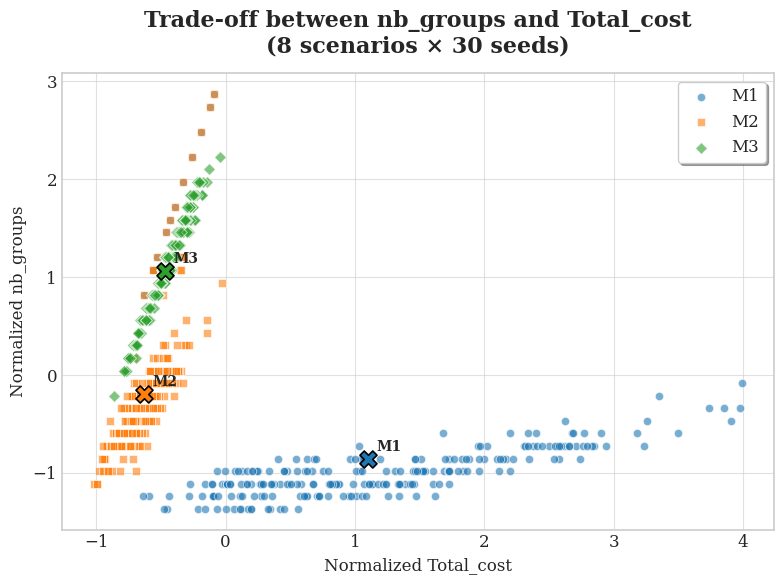

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'axes.linewidth': 1.2,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
})

# 只保留两个指标（去掉 cpu time）
x_col = 'Total_cost'
y_col = 'nb_groups'
categories = [x_col, y_col]

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 标准化（可选：如果不想标准化就直接用原值）
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df[categories].dropna())
df_scaled = df.copy()
df_scaled[categories] = data_scaled

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', 'D']

fig, ax = plt.subplots(figsize=(8, 6))

# 每个 strategy 画一组点（trade-off 图）
for idx, strategy in enumerate(df_scaled['strategy'].unique()):
    strat_data = df_scaled[df_scaled['strategy'] == strategy]
    ax.scatter(
        strat_data[x_col],
        strat_data[y_col],
        color=colors[idx],
        marker=markers[idx],
        alpha=0.6,
        label=strategy,
        edgecolors='white',
        linewidths=0.7
    )

# 同时画每个 strategy 的均值点并加标签
for idx, strategy in enumerate(df_scaled['strategy'].unique()):
    strat_data = df_scaled[df_scaled['strategy'] == strategy]
    mean_x = strat_data[x_col].mean()
    mean_y = strat_data[y_col].mean()
    ax.scatter(mean_x, mean_y,
               color=colors[idx],
               marker='X',
               s=150,
               edgecolors='black',
               linewidths=1.2,
               zorder=5)
    ax.annotate(strategy,
                xy=(mean_x, mean_y),
                xytext=(6, 6),
                textcoords='offset points',
                fontsize=10,
                fontweight='bold')

ax.set_xlabel(f'Normalized {x_col}')
ax.set_ylabel(f'Normalized {y_col}')
ax.set_title('Trade-off between nb_groups and Total_cost\n(8 scenarios × 30 seeds)',
             fontsize=16, fontweight='bold', pad=15)

ax.grid(True, color='lightgrey', linestyle='-', linewidth=0.8, alpha=0.7)
legend = ax.legend(loc='best', frameon=True, fancybox=True, shadow=True)

plt.tight_layout()
# plt.savefig('tradeoff_scatter.png', dpi=400, bbox_inches='tight',
#             facecolor='white', edgecolor='none')
plt.show()


=== M2异常高nb_groups的飘点 ===
     scenario_id  nb_groups  Total_cost  nb_scaled  cost_scaled
64             1         22        2635   1.578589     0.806784
121            2         24        2400   1.978442     0.380150
133            2         23        2560   1.778515     0.670625
142            2         22        2200   1.578589     0.017058
301            4         24        2400   1.978442     0.380150
313            4         27        2700   2.578222     0.924789
355            4         25        2500   2.178369     0.561697

找到 7 个异常样本
M1 nb_groups均值: 8.9


/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24322 (\N{CJK UNIFIED IDEOGRAPH-5F02}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/wenbo.wu/opt/anaconda3/envs/rte/lib/python3.9/site-packag

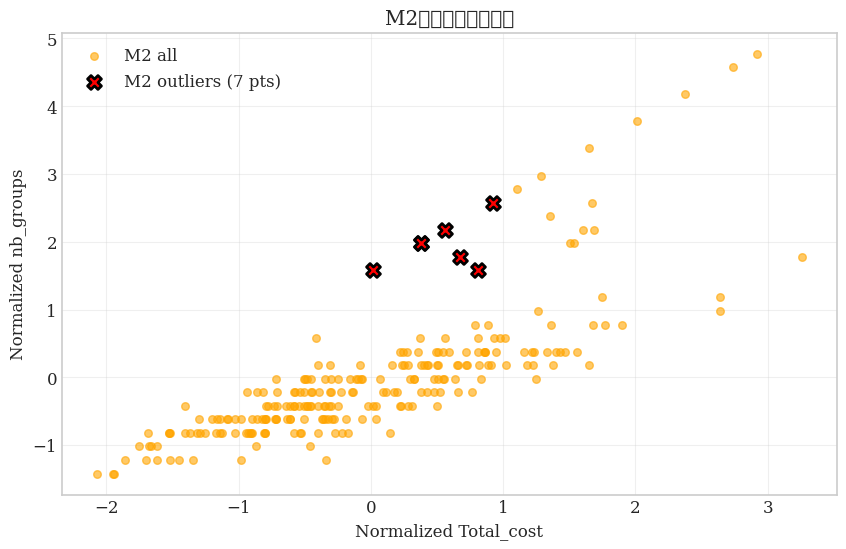

In [24]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 读取数据
df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 只看M2策略
m2_data = df[df['strategy'] == 'M2'].copy()

# 标准化（与图中一致）
scaler = StandardScaler()
scaled_cols = ['nb_groups', 'Total_cost']
m2_scaled = scaler.fit_transform(m2_data[scaled_cols])
m2_data['nb_scaled'] = m2_scaled[:, 0]  # nb_groups标准化值
m2_data['cost_scaled'] = m2_scaled[:, 1]

# 🔥 找出"飘在上方"的异常点
# 标准：nb_groups标准化值 > M1均值 + 0.5σ（明显高于M1）
m1_nb_mean = df[df['strategy']=='M1']['nb_groups'].mean()
m1_nb_std = df[df['strategy']=='M1']['nb_groups'].std()
threshold = (m1_nb_mean / m2_data['nb_groups'].mean()) * 1.2  # 20%高于M1均值

outliers = m2_data[
    (m2_data['nb_scaled'] > 1.5) &  # 高nb_groups（Y轴上）
    (m2_data['cost_scaled'] < 1.0)   # 成本中等（X轴不差）
].copy()

print("=== M2异常高nb_groups的飘点 ===")
print(outliers[['scenario_id', 'nb_groups', 'Total_cost', 'nb_scaled', 'cost_scaled']])
print(f"\n找到 {len(outliers)} 个异常样本")
print(f"M1 nb_groups均值: {m1_nb_mean:.1f}")

# 可视化确认
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,6))

# 所有M2点
ax.scatter(m2_data['cost_scaled'], m2_data['nb_scaled'], 
           c='orange', alpha=0.6, label='M2 all', s=30)

# 异常点高亮
ax.scatter(outliers['cost_scaled'], outliers['nb_scaled'], 
           c='red', s=100, marker='X', edgecolors='black', linewidth=2,
           label=f'M2 outliers ({len(outliers)} pts)')

ax.set_xlabel('Normalized Total_cost')
ax.set_ylabel('Normalized nb_groups')
ax.legend()
ax.grid(True, alpha=0.3)
plt.title('M2异常高分组点识别')
plt.show()


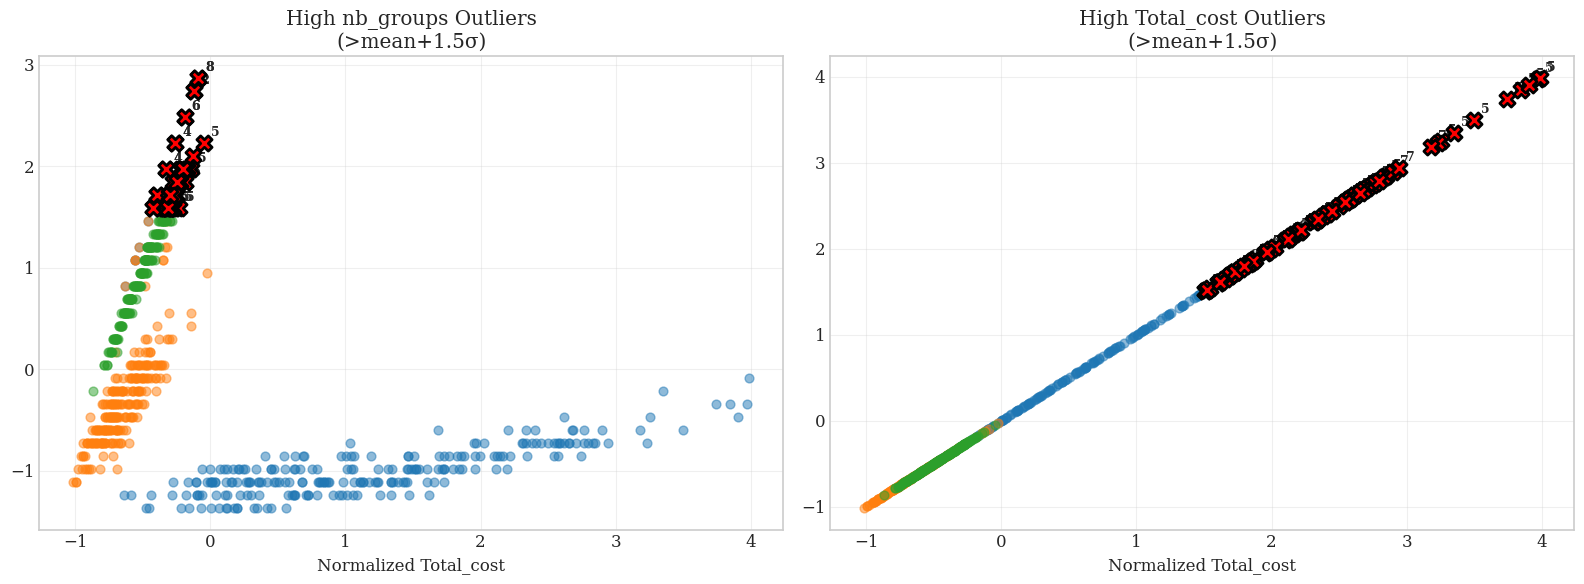

=== 所有策略异常高指标详情 ===

nb_groups outlying point (>mean+1.5σ):
    strategy  scenario_id  nb_groups  Total_cost
5         M3            1       1.59       -0.32
14        M3            1       1.59       -0.33
17        M3            1       1.97       -0.21
29        M3            1       1.59       -0.33
32        M3            1       1.84       -0.27
..       ...          ...        ...         ...
623       M3            7       1.71       -0.27
626       M3            7       1.71       -0.27
629       M3            7       1.71       -0.29
672       M1            8       2.87       -0.09
673       M2            8       2.87       -0.09

[65 rows x 4 columns]

Total_cost outlying point (>mean+1.5σ):
    strategy  scenario_id  Total_cost  Total_cost
363       M1            5        3.97        3.97
366       M1            5        1.51        1.51
369       M1            5        1.73        1.73
372       M1            5        2.40        2.40
375       M1            5        3.35 

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 🔥 标准化所有数据
scaler = StandardScaler()
scaled_cols = ['nb_groups', 'Total_cost']
df_scaled = df.copy()
df_scaled[scaled_cols] = scaler.fit_transform(df[scaled_cols])

colors = {'M1':'#1f77b4', 'M2':'#ff7f0e', 'M3':'#2ca02c'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for i, metric in enumerate(['nb_groups', 'Total_cost']):
    ax = ax1 if i==0 else ax2
    
    # 所有点
    for strategy in df['strategy'].unique():
        strat_data = df_scaled[df_scaled['strategy']==strategy]
        ax.scatter(strat_data['Total_cost'], strat_data[metric], 
                  c=colors[strategy], alpha=0.5, s=40, label=strategy)
    
    # 🔥 找出该指标异常高的点（>均值+1.5σ）
    threshold = df_scaled[metric].mean() + 1.5 * df_scaled[metric].std()
    outliers = df_scaled[df_scaled[metric] > threshold]
    
    if len(outliers) > 0:
        for _, row in outliers.iterrows():
            ax.scatter(row['Total_cost'], row[metric], 
                      c='red', s=120, marker='X', 
                      edgecolors='black', linewidth=2, zorder=5)
            # 标注scenario_id
            ax.annotate(row['scenario_id'], 
                       xy=(row['Total_cost'], row[metric]),
                       xytext=(5, 5), textcoords='offset points',
                       fontsize=9, fontweight='bold')
    
    ax.set_xlabel('Normalized Total_cost')
    ax.set_title(f'High {metric} Outliers\n(>mean+1.5σ)')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('all_strategies_outliers.png', dpi=300, bbox_inches='tight')
plt.show()

# 🔥 打印详细异常信息
print("=== 所有策略异常高指标详情 ===")
for metric in ['nb_groups', 'Total_cost']:
    print(f"\n{metric} outlying point (>mean+1.5σ):")
    threshold = df_scaled[metric].mean() + 1.5 * df_scaled[metric].std()
    outliers = df_scaled[df_scaled[metric] > threshold][['strategy', 'scenario_id', metric, 'Total_cost']]
    print(outliers.round(2))


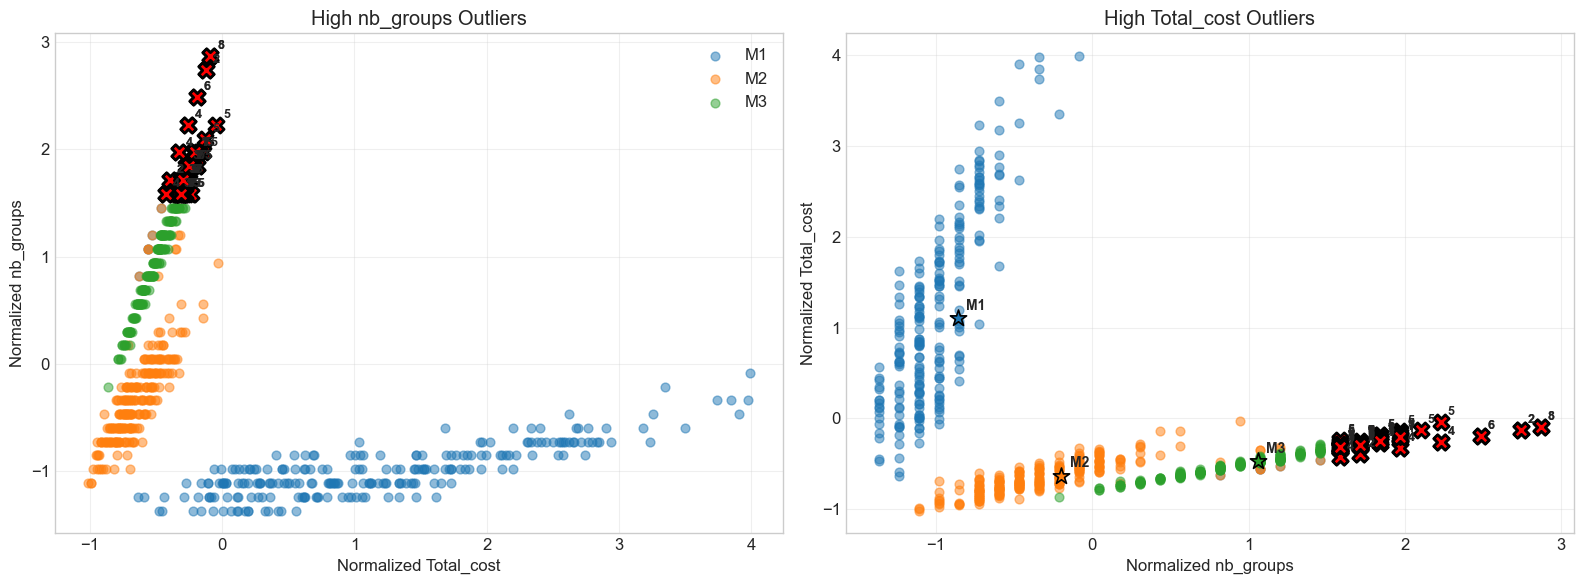

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 标准化
scaler = StandardScaler()
scaled_cols = ['nb_groups', 'Total_cost']
df_scaled = df.copy()
df_scaled[scaled_cols] = scaler.fit_transform(df[scaled_cols])

colors = {'M1':'#1f77b4', 'M2':'#ff7f0e', 'M3':'#2ca02c'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))


# 🔥 左图：X=Total_cost, Y=nb_groups 高异常
ax = ax1
for strategy in df['strategy'].unique():
    strat_data = df_scaled[df_scaled['strategy']==strategy]
    ax.scatter(strat_data['Total_cost'], strat_data['nb_groups'], 
               c=colors[strategy], alpha=0.5, s=40, label=strategy)

outliers_nb = df_scaled[df_scaled['nb_groups'] > 
                       (df_scaled['nb_groups'].mean() + 1.5*df_scaled['nb_groups'].std())]
for _, row in outliers_nb.iterrows():
    ax.scatter(row['Total_cost'], row['nb_groups'], 
               c='red', s=120, marker='X', edgecolors='black', linewidth=2)
    ax.annotate(row['scenario_id'], xy=(row['Total_cost'], row['nb_groups']),
                xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')
ax.set_xlabel('Normalized Total_cost')
ax.set_ylabel('Normalized nb_groups')
ax.set_title('High nb_groups Outliers')
ax.grid(True, alpha=0.3)
ax.legend()

# # 🔥 右图：X=nb_groups, Y=Total_cost 高异常  
# ax = ax2
# for strategy in df['strategy'].unique():
#     strat_data = df_scaled[df_scaled['strategy']==strategy]
#     ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
#                c=colors[strategy], alpha=0.5, s=40, label=strategy)

# outliers_cost = df_scaled[df_scaled['Total_cost'] > 
#                          (df_scaled['Total_cost'].mean() + 1.5*df_scaled['Total_cost'].std())]
# for _, row in outliers_cost.iterrows():
#     ax.scatter(row['nb_groups'], row['Total_cost'], 
#                c='red', s=120, marker='X', edgecolors='black', linewidth=2)
#     ax.annotate(row['scenario_id'], xy=(row['nb_groups'], row['Total_cost']),
#                 xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')
# ax.set_xlabel('Normalized nb_groups')
# ax.set_ylabel('Normalized Total_cost')
# ax.set_title('High Total_cost Outliers')
# ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig('corrected_outliers_tradeoff.png', dpi=300, bbox_inches='tight')
# plt.show()

# 🔥 右图：X=nb_groups, Y=Total_cost 高异常  
ax = ax2
for strategy in df['strategy'].unique():
    strat_data = df_scaled[df_scaled['strategy']==strategy]
    ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
               c=colors[strategy], alpha=0.5, s=40, label=strategy)

outliers_cost = df_scaled[df_scaled['nb_groups'] > 
                         (df_scaled['nb_groups'].mean() + 1.5*df_scaled['nb_groups'].std())]
for _, row in outliers_cost.iterrows():
    ax.scatter(row['nb_groups'], row['Total_cost'], 
               c='red', s=120, marker='X', edgecolors='black', linewidth=2)
    ax.annotate(row['scenario_id'], xy=(row['nb_groups'], row['Total_cost']),
                xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold')

# 🔥 加上每个 strategy 的均值点（修正版）
for strategy in df_scaled['strategy'].unique():  # 用strategy而非idx
    strat_data = df_scaled[df_scaled['strategy'] == strategy]
    mean_x = strat_data['nb_groups'].mean()      # 右图X轴=nb_groups
    mean_y = strat_data['Total_cost'].mean()     # 右图Y轴=Total_cost
    ax.scatter(mean_x, mean_y,
               color=colors[strategy],            # 用colors[strategy]
               marker='*',
               s=150,
               edgecolors='black',
               linewidths=1.2,
               zorder=5)
    ax.annotate(strategy,
                xy=(mean_x, mean_y),
                xytext=(6, 6),
                textcoords='offset points',
                fontsize=10,
                fontweight='bold')

ax.set_xlabel('Normalized nb_groups')
ax.set_ylabel('Normalized Total_cost')
ax.set_title('High Total_cost Outliers')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('corrected_outliers_tradeoff.png', dpi=300, bbox_inches='tight')
plt.show()

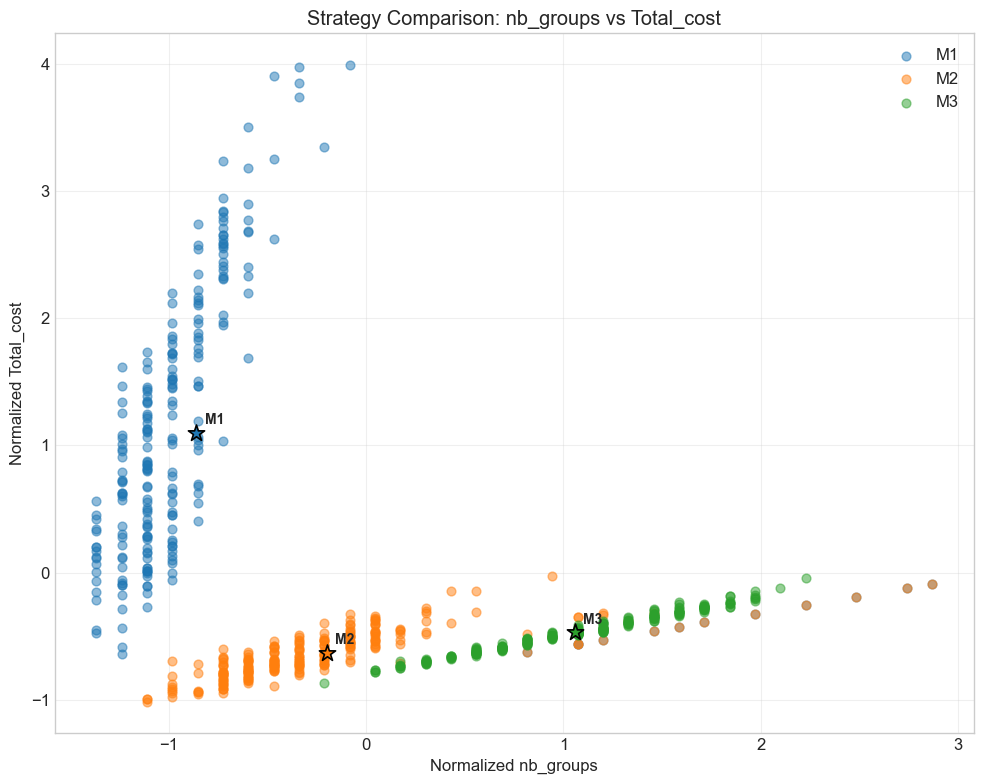

In [73]:
# ... 数据处理部分不变 ...

# 🔥 只保留右图
fig, ax = plt.subplots(1, 1, figsize=(10, 8))  # ← 只改这里

# 右图内容（你的代码）
for strategy in df['strategy'].unique():
    strat_data = df_scaled[df_scaled['strategy']==strategy]
    ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
               c=colors[strategy], alpha=0.5, s=40, label=strategy)
    

# 🔥 加上每个 strategy 的均值点（修正版）
for strategy in df_scaled['strategy'].unique():  # 用strategy而非idx
    strat_data = df_scaled[df_scaled['strategy'] == strategy]
    mean_x = strat_data['nb_groups'].mean()      # 右图X轴=nb_groups
    mean_y = strat_data['Total_cost'].mean()     # 右图Y轴=Total_cost
    ax.scatter(mean_x, mean_y,
               color=colors[strategy],            # 用colors[strategy]
               marker='*',
               s=150,
               edgecolors='black',
               linewidths=1.2,
               zorder=5)
    ax.annotate(strategy,
                xy=(mean_x, mean_y),
                xytext=(6, 6),
                textcoords='offset points',
                fontsize=10,
                fontweight='bold')

ax.set_xlabel('Normalized nb_groups')
ax.set_ylabel('Normalized Total_cost')
ax.set_title('Strategy Comparison: nb_groups vs Total_cost')
ax.grid(True, alpha=0.3)
ax.legend()  # 加个图例

plt.tight_layout()
plt.savefig('single_tradeoff.png', dpi=300, bbox_inches='tight')
plt.show()


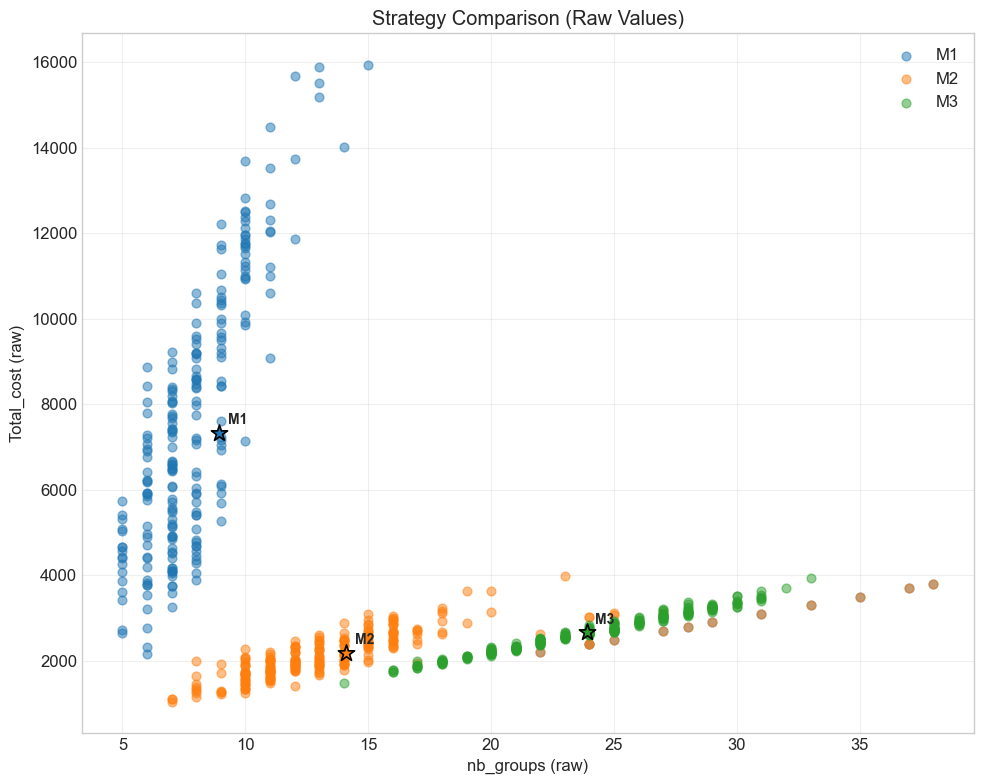

In [78]:
# no normalization version


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 🔥 直接用原始df，所有strat_data改用df
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

for strategy in df['strategy'].unique():  # df，不是df_scaled
    strat_data = df[df['strategy']==strategy]  # df，不是df_scaled
    ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
               c=colors[strategy], alpha=0.5, s=40, label=strategy)

# 均值点也用df
for strategy in df['strategy'].unique():  # df，不是df_scaled
    strat_data = df[df['strategy'] == strategy]  # df，不是df_scaled
    mean_x = strat_data['nb_groups'].mean()
    mean_y = strat_data['Total_cost'].mean()
    ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', s=150,
               edgecolors='black', linewidths=1.2, zorder=5)
    ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                textcoords='offset points', fontsize=10, fontweight='bold')

ax.set_xlabel('nb_groups (raw)')  # 改标签
ax.set_ylabel('Total_cost (raw)')
ax.set_title('Strategy Comparison (Raw Values)')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
# plt.savefig('raw_tradeoff.png', dpi=300, bbox_inches='tight')
plt.show()

=== Scenario稳定性分析（CV=std/mean，低=稳定）===
    scenario_id strategy  nb_mean  nb_std  cost_mean  cost_std     nb_cv  \
3             2       M1    9.133   7.903   4322.667   910.109  0.865324   
9             4       M1   10.567   9.008   3542.167   813.591  0.852465   
21            8       M1    8.567   5.612   7903.167  1358.465  0.655072   
15            6       M1    8.467   5.244   8132.667  2471.383  0.619346   
10            4       M2   13.467   7.583   1865.667   565.729  0.563080   
4             2       M2   13.067   6.958   1884.000   576.433  0.532486   
22            8       M2   12.600   4.966   1928.833   414.160  0.394127   
16            6       M2   12.833   4.624   2009.000   452.717  0.360321   
7             3       M2   14.967   4.255   2319.333   419.691  0.284292   
1             1       M2   14.667   3.933   2334.333   471.647  0.268153   
12            5       M1    9.833   2.465  11249.500  2830.127  0.250686   
13            5       M2   15.767   2.921   2596.

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/4102099044.py:44: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/4102099044.py:44: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/4102099044.py:44: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/4102099044.py:44: UserWarning: Glyph 36234 (\N{CJK UNIFIED IDEOGRAPH-8D8A}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_6975/4102099044.py:44: UserWarning: Glyph 30702 (\N{CJK UNIFIED IDEOGRAPH-77EE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipyker

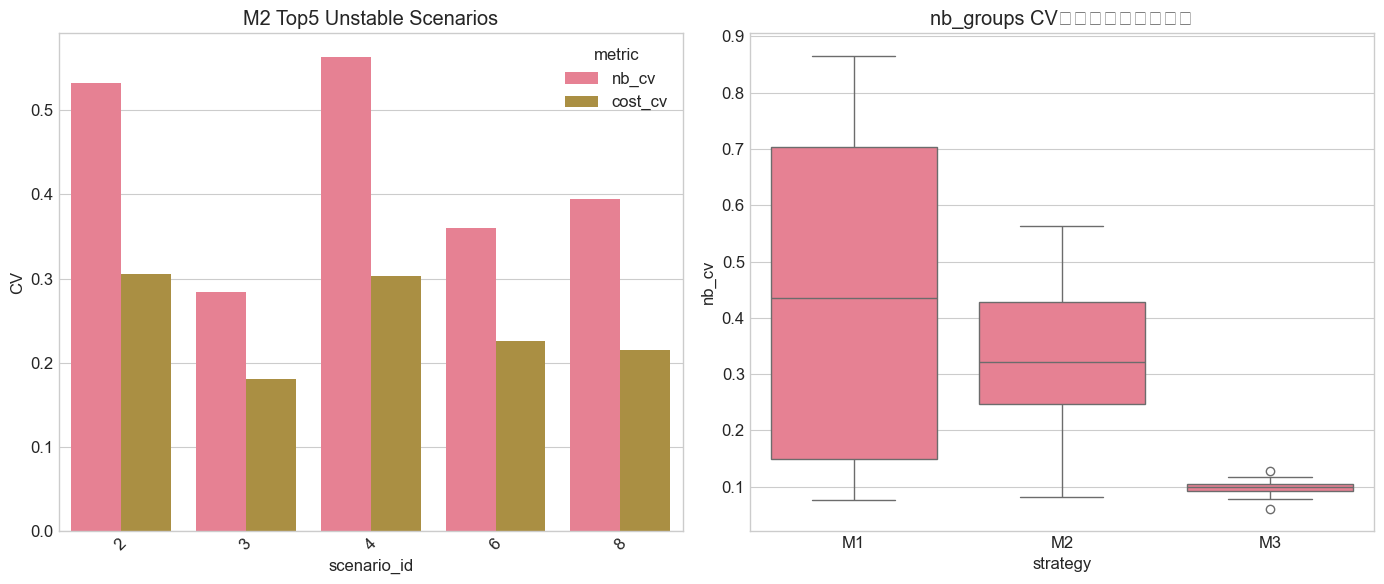

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 🔥 手动计算mean和std，避免MultiIndex
scenario_stats = df.groupby(['scenario_id', 'strategy'])[['nb_groups', 'Total_cost']].agg({
    'nb_groups': ['mean', 'std'],
    'Total_cost': ['mean', 'std']
}).round(3)

# 🔥 扁平列名
scenario_stats.columns = ['nb_mean', 'nb_std', 'cost_mean', 'cost_std']
scenario_stats = scenario_stats.reset_index()

# 🔥 计算CV
scenario_stats['nb_cv'] = scenario_stats['nb_std'] / scenario_stats['nb_mean']
scenario_stats['cost_cv'] = scenario_stats['cost_std'] / scenario_stats['cost_mean']

print("=== Scenario稳定性分析（CV=std/mean，低=稳定）===")
print(scenario_stats.sort_values('nb_cv', ascending=False))

# 🔥 M2最不稳定Top5
m2_unstable = scenario_stats[scenario_stats['strategy']=='M2'].sort_values('nb_cv', ascending=False).head(5)
print("\n=== M2分组数最不稳定Top5 Scenario ===")
print(m2_unstable[['scenario_id', 'nb_cv', 'cost_cv', 'nb_mean', 'nb_std']])

# 🔥 可视化
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# M2 CV条形图
m2_cv_long = m2_unstable.melt(id_vars='scenario_id', value_vars=['nb_cv', 'cost_cv'], 
                              var_name='metric', value_name='CV')
sns.barplot(data=m2_cv_long, x='scenario_id', y='CV', hue='metric', ax=ax1)
ax1.set_title('M2 Top5 Unstable Scenarios')
ax1.tick_params(axis='x', rotation=45)

# 所有策略CV对比
sns.boxplot(data=scenario_stats, x='strategy', y='nb_cv', ax=ax2)
ax2.set_title('nb_groups CV分布（越矮越稳定）')

plt.tight_layout()
plt.savefig('scenario_m2_instability.png', dpi=300, bbox_inches='tight')
plt.show()


数据形状: (720, 13)
列名: ['scenario_id', 'density', 'seed', 'strategy', 'density.1', 'periodicity_cv', 'clustering_tendency', 'nb_groups', 'Avg_tasks/group', 'CP_cost', 'Total_cost', 'leakage_reduction_pct', 'total_clustering_cpu_s']
scenario_id 唯一值: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

=== 计算复合评分 ===
前5行评分:
   scenario_id strategy  Total_cost  nb_groups  composite
0            1       M1        6905          6       75.0
1            1       M2        1900         10       36.0
2            1       M3        2690         25       99.0
3            1       M1        7240          9      105.0
4            1       M2        2960         16       95.0

=== 🎉 每个场景最优策略 ===
|   scenario_id | strategy   |   composite |   Total_cost |   nb_groups |
|--------------:|:-----------|------------:|-------------:|------------:|
|             1 | M2         |          33 |         1530 |          11 |
|             2 | M2         |      

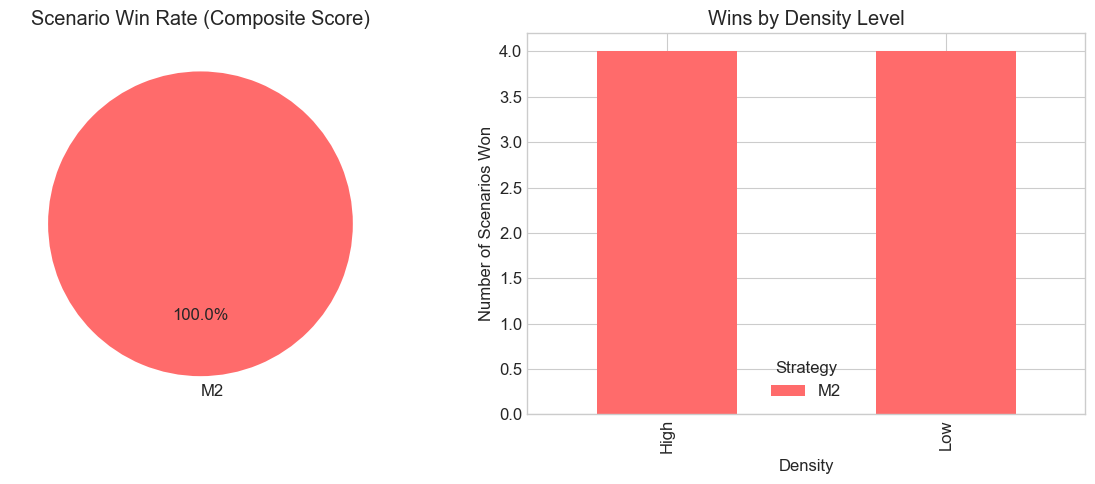


=== 🚀 场景推荐决策 ===
Density-based:
  High: M2
  Low: M2

完整推荐 (ID→策略):
  ID1 (Low-Periodic-Uniform): M2
  ID2 (Low-Periodic-Clustered): M2
  ID3 (Low-Aperiodic-Uniform): M2
  ID4 (Low-Aperiodic-Clustered): M2
  ID5 (High-Periodic-Uniform): M2
  ID6 (High-Periodic-Clustered): M2
  ID7 (High-Aperiodic-Uniform): M2
  ID8 (High-Aperiodic-Clustered): M2


In [81]:
# 🔥 修复版本：核心框架分析 (去掉CPU bug + 场景因子映射修正)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

print(f"数据形状: {df.shape}")
print(f"列名: {df.columns.tolist()}")
print(f"scenario_id 唯一值: {sorted(df['scenario_id'].unique())}")

# ========================================
# 1. 排名计算 (只用2指标，权重: cost=2x, groups=1x)
# ========================================
print("\n=== 计算复合评分 ===")
df['Total_cost_rank'] = df.groupby('scenario_id')['Total_cost'].rank(method='min')
df['nb_groups_rank'] = df.groupby('scenario_id')['nb_groups'].rank(method='min')
df['composite'] = df['Total_cost_rank'] * 1 + df['nb_groups_rank'] * 1  # 去掉CPU

print("前5行评分:")
print(df[['scenario_id', 'strategy', 'Total_cost', 'nb_groups', 'composite']].head())

# ========================================
# 2. 每个场景最优策略
# ========================================
best_per_scen = df.loc[df.groupby('scenario_id')['composite'].idxmin()][
    ['scenario_id', 'strategy', 'composite', 'Total_cost', 'nb_groups']
].round(1)

print("\n=== 🎉 每个场景最优策略 ===")
print(best_per_scen.sort_values('scenario_id').to_markdown(index=False))

# 胜率统计
win_counts = best_per_scen['strategy'].value_counts()
print(f"\n胜率: {win_counts.to_dict()} ({len(win_counts)}/8场景)")

# ========================================
# 3. 🔥 修复：场景因子映射 (正确4列构造)
# ========================================
scenario_factors = {
    1: ['Low', 'Periodic', 'Uniform', 30],
    2: ['Low', 'Periodic', 'Clustered', 30],
    3: ['Low', 'Aperiodic', 'Uniform', 30],
    4: ['Low', 'Aperiodic', 'Clustered', 30],
    5: ['High', 'Periodic', 'Uniform', 150],
    6: ['High', 'Periodic', 'Clustered', 150],
    7: ['High', 'Aperiodic', 'Uniform', 150],
    8: ['High', 'Aperiodic', 'Clustered', 150]
}

# 正确构造DataFrame
factor_df = pd.DataFrame([
    [k] + scenario_factors[k] for k in scenario_factors.keys()
], columns=['scenario_id', 'Density', 'Periodicity', 'Clustering', 'Expected_I'])

# 🔥 合并因子信息
best_with_factors = best_per_scen.merge(factor_df, on='scenario_id')
print("\n=== 按DOE因子分组胜率 ===")
win_by_factor = best_with_factors.groupby(['strategy', 'Density', 'Periodicity', 'Clustering']).size()
print(win_by_factor.unstack(fill_value=0).to_markdown())

# ========================================
# 4. 主效应分析表
# ========================================
df_factors = df.merge(factor_df, on='scenario_id')
main_effects = df_factors.groupby(['Density', 'strategy'])[['nb_groups', 'Total_cost', 'composite']].mean().round(1)
print("\n=== 主效应：Density影响 ===")
print(main_effects.to_markdown())

# ========================================
# 5. 胜率饼图 (修复颜色+图例)
# ========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 饼图：总体胜率
colors = {'M1': '#45B7D1', 'M2': '#FF6B6B', 'M3': '#4ECDC4'}
wedges, texts, autotexts = ax1.pie(win_counts.values, 
                                   labels=win_counts.index, 
                                   autopct='%1.1f%%',
                                   colors=[colors[s] for s in win_counts.index],
                                   startangle=90)
ax1.set_title('Scenario Win Rate (Composite Score)')

# 条形图：按Density分组
win_density = best_with_factors.groupby(['Density', 'strategy']).size().unstack(fill_value=0)
win_density.plot(kind='bar', ax=ax2, color=[colors.get(c, 'gray') for c in win_density.columns])
ax2.set_title('Wins by Density Level')
ax2.set_ylabel('Number of Scenarios Won')
ax2.legend(title='Strategy')
plt.tight_layout()
plt.savefig('scenario_winners_fixed.png', dpi=300, bbox_inches='tight')
plt.show()

# ========================================
# 6. 决策推荐
# ========================================
print("\n=== 🚀 场景推荐决策 ===")
density_recs = best_with_factors.groupby('Density')['strategy'].agg(lambda x: x.mode()[0]).to_dict()
print("Density-based:")
for density, strat in density_recs.items():
    print(f"  {density}: {strat}")

print("\n完整推荐 (ID→策略):")
rec_dict = best_with_factors.set_index('scenario_id')['strategy'].to_dict()
for sid in sorted(rec_dict.keys()):
    factors = factor_df[factor_df['scenario_id']==sid][['Density','Periodicity','Clustering']].values[0]
    print(f"  ID{sid} ({factors[0]}-{factors[1]}-{factors[2]}): {rec_dict[sid]}")


In [ ]:
# 🔥 修复帕累托非支配排序 - 简洁无错版
import pandas as pd
import numpy as np

def pareto_non_dominated(df_group):
    """计算非支配解 (min目标) - 简洁版"""
    metrics = ['Total_cost', 'nb_groups']
    scores = df_group[metrics].values
    n = len(scores)
    
    # 标记被支配的解
    is_dominated = np.zeros(n, dtype=bool)
    
    for i in range(n):
        for j in range(n):
            if i == j: 
                continue
            # j支配i: j≤i(所有指标) 且 j<i(至少一个)
            if all(scores[j] <= scores[i]) and any(scores[j] < scores[i]):
                is_dominated[i] = True
                break
    
    return df_group[~is_dominated].copy()

# ========================================
# 主分析流程
# ========================================
print("=== 🎯 帕累托前沿分析 ===")

pareto_results = []
for scen_id, group in df.groupby('scenario_id'):
    pareto_best = pareto_non_dominated(group)
    
    # 记录每个场景的帕累托最优策略
    strategies = pareto_best['strategy'].tolist()
    print(f"场景{scen_id}: {strategies}")
    
    pareto_results.append(pareto_best)

# 合并结果
pareto_df = pd.concat(pareto_results, ignore_index=True)

# 帕累托胜率统计
pareto_wins = pareto_df['strategy'].value_counts()
print(f"\n帕累托胜率: {pareto_wins.to_dict()}")

# ========================================
# 详细性能表
# ========================================
print("\n=== 每个场景帕累托最优解 ===")
for scen_id, group in df.groupby('scenario_id'):
    pareto_best = pareto_non_dominated(group)

    print(f"\n场景 {scen_id}:")
    print(pareto_best[['strategy', 'Total_cost', 'nb_groups']].round(1).to_markdown(index=False))

# ========================================
# 按Density分组帕累托表现
# ========================================
# 使用之前修复的因子映射
factor_df = pd.DataFrame([
    [1, 'Low', 'Periodic', 'Uniform', 30],
    [2, 'Low', 'Periodic', 'Clustered', 30],
    [3, 'Low', 'Aperiodic', 'Uniform', 30],
    [4, 'Low', 'Aperiodic', 'Clustered', 30],
    [5, 'High', 'Periodic', 'Uniform', 150],
    [6, 'High', 'Periodic', 'Clustered', 150],
    [7, 'High', 'Aperiodic', 'Uniform', 150],
    [8, 'High', 'Aperiodic', 'Clustered', 150]
], columns=['scenario_id', 'Density', 'Periodicity', 'Clustering', 'Expected_I'])

pareto_with_factors = pareto_df.merge(factor_df, on='scenario_id')
print("\n=== 按Density分组帕累托胜率 ===")
print(pareto_with_factors.groupby(['Density', 'strategy']).size().unstack(fill_value=0).to_markdown())


=== 🎯 帕累托前沿分析 ===
场景1: ['M2', 'M1', 'M1', 'M2']
场景2: ['M2', 'M1']
场景3: ['M1', 'M2', 'M1']
场景4: ['M2', 'M1', 'M1']
场景5: ['M1', 'M1', 'M2']
场景6: ['M2', 'M1', 'M2']
场景7: ['M1', 'M1', 'M1', 'M2']
场景8: ['M2', 'M1', 'M2', 'M1']

帕累托胜率: {'M1': 15, 'M2': 11}

=== 每个场景帕累托最优解 ===

场景 1:
| strategy   |   Total_cost |   nb_groups |
|:-----------|-------------:|------------:|
| M2         |         1900 |          10 |
| M1         |         4915 |           7 |
| M1         |         5900 |           6 |
| M2         |         1530 |          11 |

场景 2:
| strategy   |   Total_cost |   nb_groups |
|:-----------|-------------:|------------:|
| M2         |         1050 |           7 |
| M1         |         3425 |           5 |

场景 3:
| strategy   |   Total_cost |   nb_groups |
|:-----------|-------------:|------------:|
| M1         |         5915 |           6 |
| M2         |         1695 |          11 |
| M1         |         4095 |           7 |

场景 4:
| strategy   |   Total_cost |   nb_groups

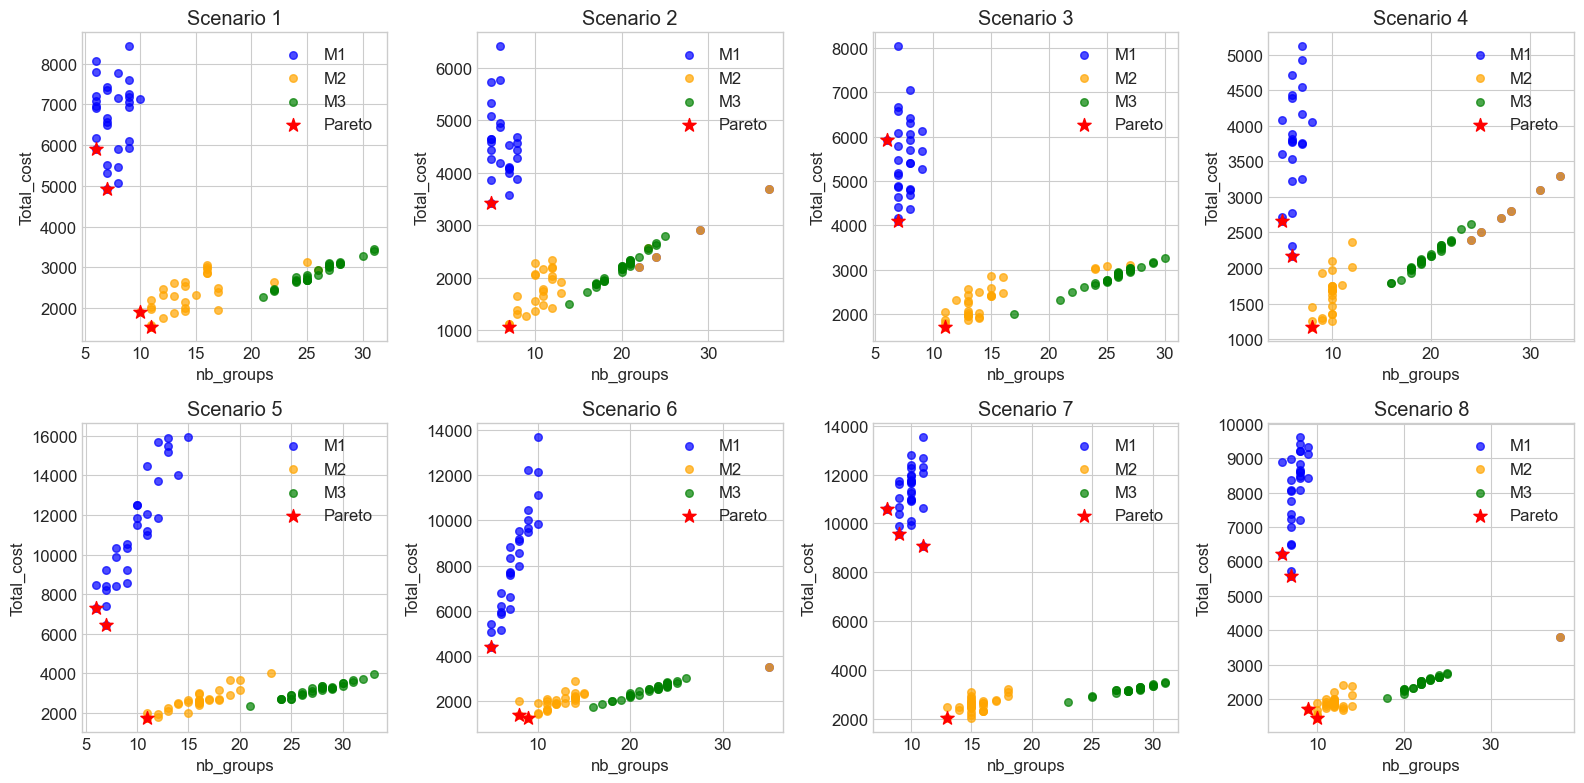

In [86]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//4, i%4]
    colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}
    for strat, subg in group.groupby('strategy'):
        ax.scatter(subg['nb_groups'], subg['Total_cost'], 
                  c=colors[strat], label=strat, alpha=0.7, s=30)
    
    pareto_best = pareto_non_dominated(group)
    pareto_best.plot(x='nb_groups', y='Total_cost', kind='scatter', 
                    c='red', s=100, marker='*', ax=ax, label='Pareto')
    ax.set_title(f'Scenario {scen}')
    ax.legend()

plt.tight_layout()
# plt.savefig('pareto_frontiers.png', dpi=300)
plt.show()


In [4]:
import pandas as pd
import numpy as np
from scipy import stats

# 你的 Pareto 函数（保持不变）
def pareto_non_dominated(df_group):
    metrics = ['Total_cost', 'nb_groups']
    scores = df_group[metrics].values
    n = len(scores)
    is_dominated = np.zeros(n, dtype=bool)
    for i in range(n):
        for j in range(n):
            if i == j: continue
            if all(scores[j] <= scores[i]) and any(scores[j] < scores[i]):
                is_dominated[i] = True
                break
    return df_group[~is_dominated].copy()

# 你的 factor_df
factor_df = pd.DataFrame([
    [1, 'Low', 'Periodic', 'Uniform', 30],
    [2, 'Low', 'Periodic', 'Clustered', 30],
    [3, 'Low', 'Aperiodic', 'Uniform', 30],
    [4, 'Low', 'Aperiodic', 'Clustered', 30],
    [5, 'High', 'Periodic', 'Uniform', 150],
    [6, 'High', 'Periodic', 'Clustered', 150],
    [7, 'High', 'Aperiodic', 'Uniform', 150],
    [8, 'High', 'Aperiodic', 'Clustered', 150]
], columns=['scenario_id', 'Density', 'Periodicity', 'Clustering', 'Expected_I'])

print("=== 🎯 场景分析开始 ===")

# ========================================
# 实验 1：权重扫描
# ========================================
scenarios = df['scenario_id'].unique()
weights = np.arange(0.1, 1.0, 0.1)

scenario_summary = df.groupby(['scenario_id', 'strategy']).agg({
    'Total_cost': 'mean', 
    'nb_groups': 'mean'
}).reset_index()

weight_results = []
for scenario_id in scenarios:
    scen_data = scenario_summary[scenario_summary['scenario_id'] == scenario_id]
    for w_cost in weights:
        scores = {}
        for _, row in scen_data.iterrows():
            strategy = row['strategy']
            score = w_cost * row['Total_cost'] + (1 - w_cost) * row['nb_groups']
            scores[strategy] = score
        best_strategy = min(scores, key=scores.get)
        weight_results.append({
            'scenario_id': scenario_id, 
            'w_cost': f"{w_cost:.1f}",
            'best': best_strategy
        })

weight_df = pd.DataFrame(weight_results)
weight_pivot = weight_df.pivot(index='scenario_id', columns='w_cost', values='best').fillna('')
print("\n📊 权重敏感性表 (复制到论文):")
print(weight_pivot.to_markdown())

# ========================================
# 实验 2：场景分解
# ========================================
scenario_perf = scenario_summary.merge(factor_df, on='scenario_id', how='left')

m1_data = scenario_perf[scenario_perf['strategy'] == 'M1']
m2_data = scenario_perf[scenario_perf['strategy'] == 'M2']
m1_m2_comparison = m1_data[['scenario_id', 'Total_cost', 'nb_groups', 'Density', 'Clustering']].\
                   merge(m2_data[['scenario_id', 'Total_cost', 'nb_groups']], 
                         on='scenario_id', suffixes=('_M1', '_M2'))

m1_m2_comparison['density_num'] = m1_m2_comparison['Density'].map({'Low': 0.2, 'High': 0.8})
m1_m2_comparison['clustering_num'] = m1_m2_comparison['Clustering'].map({'Uniform': 0, 'Clustered': 1})

if len(m1_m2_comparison) >= 2:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        m1_m2_comparison['density_num'], 
        m1_m2_comparison['Total_cost_M1'] - m1_m2_comparison['Total_cost_M2']
    )
    print(f"\n📈 回归分析: Δcost_M1-M2 = {slope:.2f}×density {intercept:+.1f} (R²={r_value**2:.3f})")

group_stats = scenario_perf.groupby(['Density', 'Clustering', 'strategy'])[['Total_cost', 'nb_groups']].mean().round(1)
print("\n📊 分组性能表:")
print(group_stats.to_markdown())

# ========================================
# 实验 3：经济影响
# ========================================
def business_score(row):
    cost = row['Total_cost']
    groups = row['nb_groups']
    setup_cost_per_group = 500
    dispatch_limit = 15
    overtime_penalty = 200
    return -(cost + groups * setup_cost_per_group + max(0, groups-dispatch_limit) * overtime_penalty)

scenario_summary['business_score'] = scenario_summary.apply(business_score, axis=1)

# 每个场景赢家
scenario_winners = scenario_summary.loc[scenario_summary.groupby('scenario_id')['business_score'].idxmax()]
print("\n🏆 业务赢家表:")
print(scenario_winners[['scenario_id', 'strategy', 'business_score', 'Total_cost', 'nb_groups']].round(1).to_markdown(index=False))

# 胜率统计
win_count = scenario_winners['strategy'].value_counts()
print(f"\n📊 总体胜率: {win_count.to_dict()}")

# ========================================
# LaTeX 兼容输出（纯文本）
# ========================================
print("\n=== 📄 论文 LaTeX 表格（手动复制）===")
print("\n权重表 (Table \\ref{tab:weights}):")
print(weight_pivot.to_string())

print("\n分组表 (Table \\ref{tab:groups}):")
print(group_stats.to_string())

print("\n赢家表 (Table \\ref{tab:winners}):")
print(scenario_winners[['scenario_id', 'strategy', 'business_score']].round(1).to_string(index=False))

print("\n✅ 分析完成！所有结果已输出，无需额外依赖")


=== 🎯 场景分析开始 ===

📊 权重敏感性表 (复制到论文):
|   scenario_id | 0.1   | 0.2   | 0.3   | 0.4   | 0.5   | 0.6   | 0.7   | 0.8   | 0.9   |
|--------------:|:------|:------|:------|:------|:------|:------|:------|:------|:------|
|             1 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             2 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             3 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             4 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             5 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             6 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             7 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             8 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |

📈 回归分析: Δcost_M1-M2 = 7405.35×density +1444.7 (R²=0.783)

📊 分组性

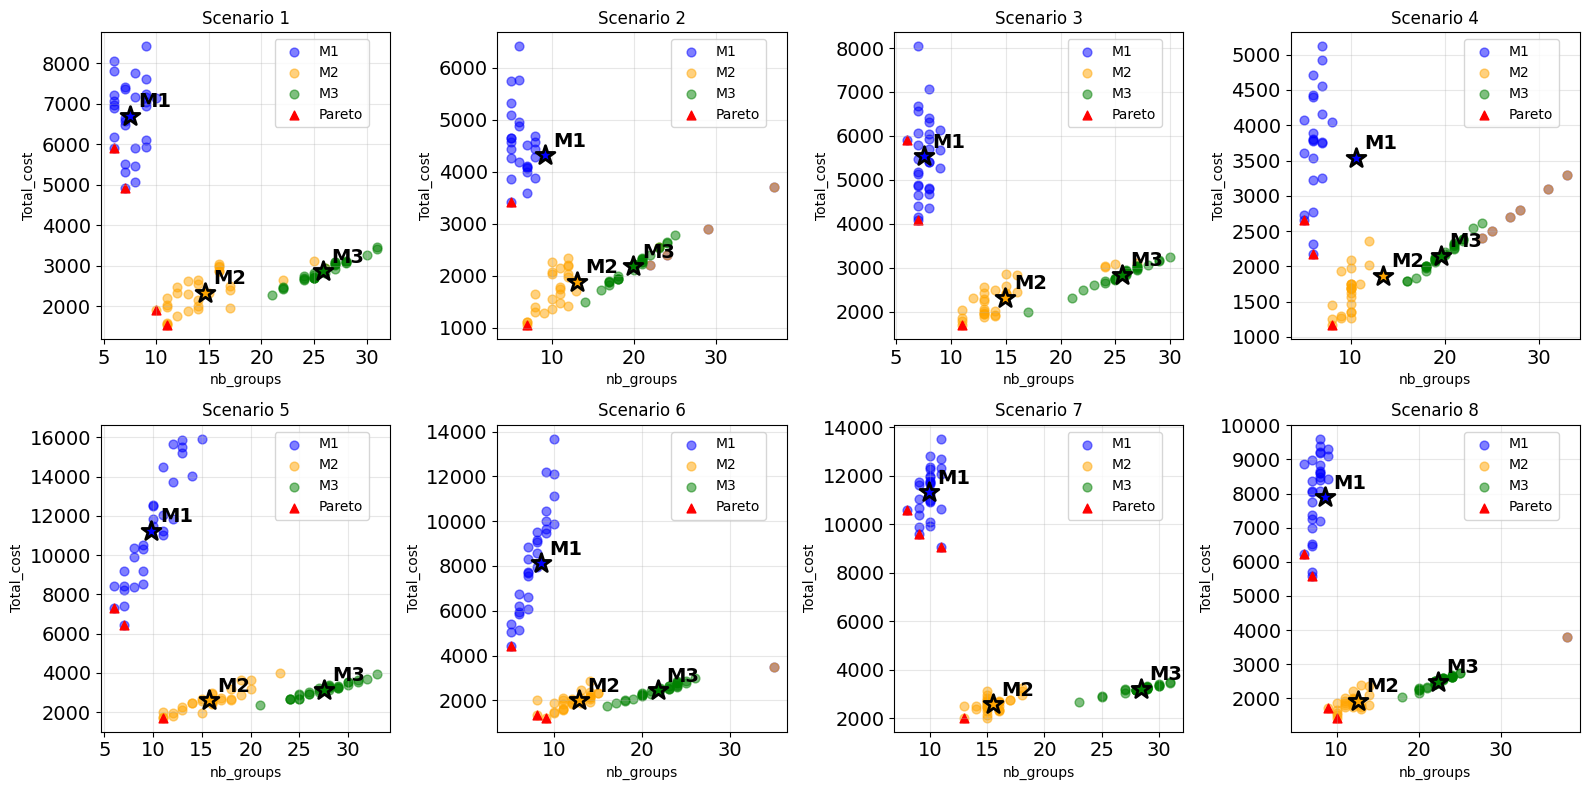

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}

for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//4, i%4]
    
    # 散点（同原代码）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
                  c=colors[strategy], alpha=0.5, s=40, label=strategy)
    
    # 均值★ + 标签（你的style！）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        mean_x = strat_data['nb_groups'].mean()
        mean_y = strat_data['Total_cost'].mean()
        ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', 
                  s=200, edgecolors='black', linewidths=2, zorder=5)
        ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                   textcoords='offset points', fontsize=14, fontweight='bold')
    
    # Pareto红★
    pareto_best = pareto_non_dominated(group)
    pareto_best.plot(x='nb_groups', y='Total_cost', kind='scatter', fontsize=14,
                    c='red', s=40, marker='^', ax=ax, label='Pareto')
    
    ax.set_title(f'Scenario {scen}')
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(0.95, 1))

plt.tight_layout()
plt.savefig('pareto_with_means_annotated.png', dpi=300, bbox_inches='tight')
plt.show()



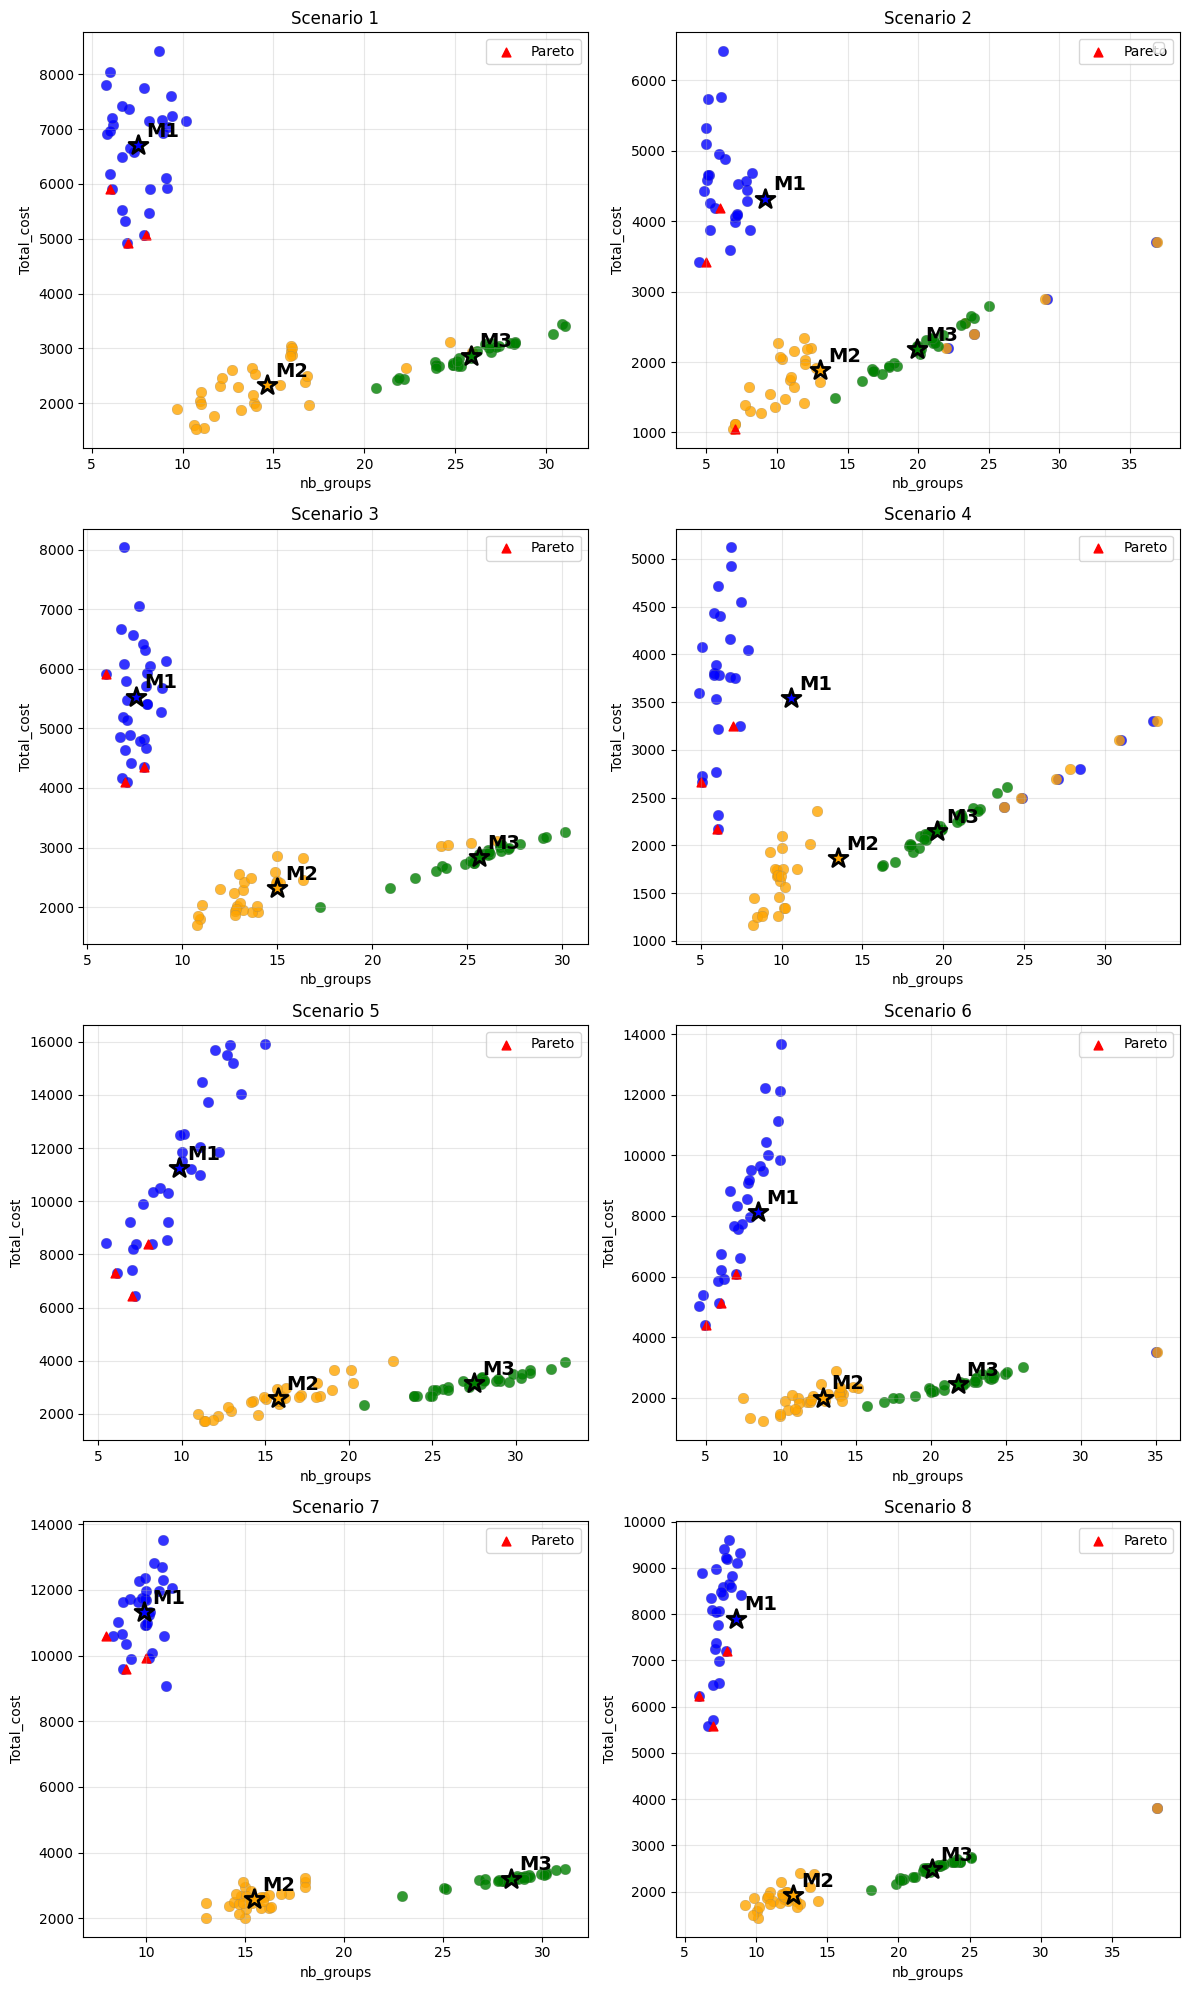

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(12, 20))
colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}

handles = []  # 收集唯一handle
labels = []

for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//2, i%2]
    
    # 只散点加label，收集handle
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        # h = ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
        #               c=colors[strategy], alpha=0.8, s=60, label=strategy)
        # handles.append(h)  # 只加一次

        jitter = np.random.normal(0, 0.2, len(strat_data))
        ax.scatter(strat_data['nb_groups'] + jitter, strat_data['Total_cost'], 
                c=colors[strategy], alpha=0.8, s=60, edgecolors='gray', linewidth=0.2)

    # 均值★ 无label
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        mean_x = strat_data['nb_groups'].mean()
        mean_y = strat_data['Total_cost'].mean()
        ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', 
                  s=200, edgecolors='black', linewidths=2, zorder=5)
        ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                   textcoords='offset points', fontsize=14, fontweight='bold')
    
    # Pareto（若有红，改成strategy色或zorder高）
    pareto_best = pareto_non_dominated(group)
    pareto_best.plot(x='nb_groups', y='Total_cost', kind='scatter', 
                    c='red', s=40, marker='^', ax=ax, label='Pareto')  # 或去label

    ax.set_title(f'Scenario {scen}')
    ax.grid(True, alpha=0.3)
    # 暂不加本地legend

# 全局唯一legend（只3种+红，共4）
handles = handles[:3]  # 确保只M1 M2 M3
labels = ['M1', 'M2', 'M3']
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.98, 0.98))
# Pareto若需，加红handle

plt.tight_layout()
# plt.savefig('pareto_clean_colors.png', dpi=300, bbox_inches='tight')
plt.show()

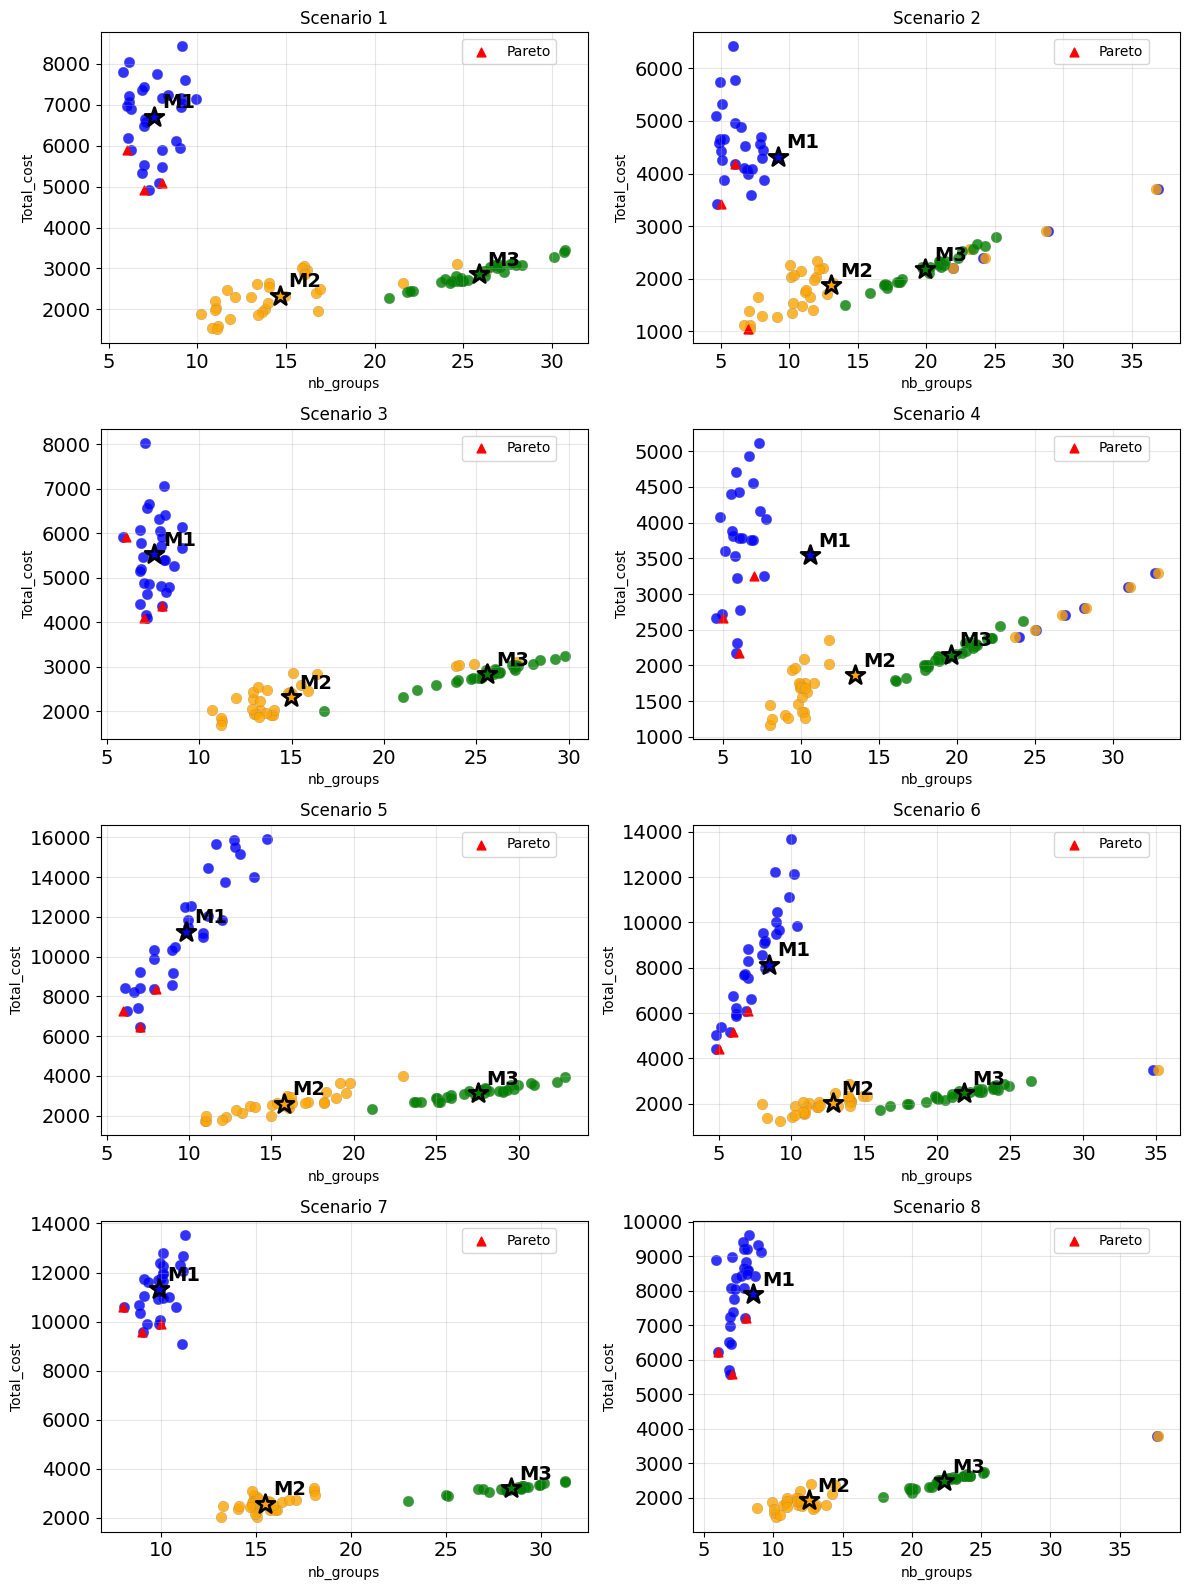

In [58]:
# new

fig, axes = plt.subplots(4, 2, figsize=(12, 16))  # 改为4行2列，高度增至16
colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}

for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//2, i%2]  # 改为行优先：i//2为行，i%2为列
    
    # 散点（同原代码）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        # ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
        #           c=colors[strategy], alpha=0.5, s=40, label=strategy)

        jitter = np.random.normal(0, 0.2, len(strat_data))
        ax.scatter(strat_data['nb_groups'] + jitter, strat_data['Total_cost'], 
                c=colors[strategy], alpha=0.8, s=60, edgecolors='gray', linewidth=0.2)
    
    # 均值★ + 标签（你的style！）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        mean_x = strat_data['nb_groups'].mean()
        mean_y = strat_data['Total_cost'].mean()
        ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', 
                  s=200, edgecolors='black', linewidths=2, zorder=5)
        ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                   textcoords='offset points', fontsize=14, fontweight='bold')
    
    # Pareto红★
    pareto_best = pareto_non_dominated(group)
    pareto_best.plot(x='nb_groups', y='Total_cost', kind='scatter', fontsize=14,
                    c='red', s=40, marker='^', ax=ax, label='Pareto')
    
    ax.set_title(f'Scenario {scen}')
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(0.95, 1))

plt.tight_layout()
# plt.savefig('pareto_4x2_layout.png', dpi=300, bbox_inches='tight')  # 新文件名
plt.show()

In [48]:
for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    print(f"\n=== Scenario {scen} ===")
    strats = group['strategy'].unique()
    print("unique():", strats)
    print("所有 strategy 值（raw）:")
    for s in group['strategy']:
        print(repr(s), len(repr(s)), type(s))  # 显示空格/None/特殊char
    print("有无未知strategy:", any(s not in colors for s in strats))
    
    # 过滤只M1-3绘图
    valid_group = group[group['strategy'].isin(['M1','M2','M3'])]
    print("过滤后行数:", len(valid_group), "vs 原", len(group))


=== Scenario 1 ===
unique(): ['M1' 'M2' 'M3']
所有 strategy 值（raw）:
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <class 'str'>
'M1' 4 <class 'str'>
'M2' 4 <class 'str'>
'M3' 4 <c

In [8]:
# 检查所有策略颜色和离群点
print("策略颜色:", colors)
print("\n每个scenario离群点（>均值+2std）：")
for scen, group in df.groupby('scenario_id'):
    mean_x, std_x = group['nb_groups'].mean(), group['nb_groups'].std()
    outliers = group[(group['nb_groups']>mean_x+2*std_x) | 
                     (group['Total_cost']>group['Total_cost'].mean()+2*group['Total_cost'].std())]
    if len(outliers)>0:
        print(f"Scenario {scen}: {len(outliers)} outliers from {outliers['strategy'].value_counts()}")


策略颜色: {'M1': 'blue', 'M2': 'orange', 'M3': 'green'}

每个scenario离群点（>均值+2std）：
Scenario 1: 1 outliers from strategy
M1    1
Name: count, dtype: int64
Scenario 2: 5 outliers from strategy
M1    4
M2    1
Name: count, dtype: int64
Scenario 3: 3 outliers from strategy
M1    3
Name: count, dtype: int64
Scenario 4: 10 outliers from strategy
M1    8
M2    2
Name: count, dtype: int64
Scenario 5: 6 outliers from strategy
M1    6
Name: count, dtype: int64
Scenario 6: 6 outliers from strategy
M1    5
M2    1
Name: count, dtype: int64
Scenario 8: 2 outliers from strategy
M1    1
M2    1
Name: count, dtype: int64


In [7]:
# M2 compared to M1 and M3
import pandas as pd

results = []
for scen, group in df.groupby('scenario_id'):
    means = group.groupby('strategy')[['nb_groups', 'Total_cost']].mean()
    
    if all(s in means.index for s in ['M1','M2','M3']):
        m1 = means.loc['M1']
        m2 = means.loc['M2']
        m3 = means.loc['M3']
        
        # 相对 M1
        red_m1_groups = (m2['nb_groups'] - m1['nb_groups']) / m1['nb_groups'] * 100
        red_m1_cost   = (m2['Total_cost'] - m1['Total_cost']) / m1['Total_cost'] * 100
        
        # 相对 M3
        red_m3_groups = (m2['nb_groups'] - m3['nb_groups']) / m3['nb_groups'] * 100
        red_m3_cost   = (m2['Total_cost'] - m3['Total_cost']) / m3['Total_cost'] * 100
        
        results.append({
            'scenario': scen,
            'M2 vs M1 (groups %)': red_m1_groups,
            'M2 vs M1 (cost %)': red_m1_cost,
            'M2 vs M3 (groups %)': red_m3_groups,
            'M2 vs M3 (cost %)': red_m3_cost
        })

results_df = pd.DataFrame(results)
print(results_df.round(2))

   scenario  M2 vs M1 (groups %)  M2 vs M1 (cost %)  M2 vs M3 (groups %)  \
0         1                94.69             -65.21               -43.30   
1         2                43.07             -56.42               -34.45   
2         3                97.80             -58.08               -41.54   
3         4                27.44             -47.33               -31.41   
4         5                60.34             -76.92               -42.67   
5         6                51.57             -75.30               -41.22   
6         7                56.23             -77.13               -45.54   
7         8                47.08             -75.59               -43.58   

   M2 vs M3 (cost %)  
0             -18.50  
1             -13.56  
2             -18.33  
3             -13.32  
4             -17.41  
5             -18.28  
6             -19.36  
7             -22.50  


In [ ]:
# M1 compared to M2 and M3
results = []

for scen, group in df.groupby('scenario_id'):
    means = group.groupby('strategy')[['nb_groups', 'Total_cost']].mean()
    
    if all(s in means.index for s in ['M1','M2','M3']):
        m1 = means.loc['M1']
        m2 = means.loc['M2']
        m3 = means.loc['M3']
        
        # 相对 M2
        red_m2_groups = (m1['nb_groups'] - m2['nb_groups']) / m2['nb_groups'] * 100
        red_m2_cost   = (m1['Total_cost'] - m2['Total_cost']) / m2['Total_cost'] * 100
        
        # 相对 M3
        red_m3_groups = (m1['nb_groups'] - m3['nb_groups']) / m3['nb_groups'] * 100
        red_m3_cost   = (m1['Total_cost'] - m3['Total_cost']) / m3['Total_cost'] * 100
        
        results.append({
            'scenario': scen,
            'M1 vs M2 (groups %)': red_m2_groups,
            'M1 vs M2 (cost %)': red_m2_cost,
            'M1 vs M3 (groups %)': red_m3_groups,
            'M1 vs M3 (cost %)': red_m3_cost
        })

results_df = pd.DataFrame(results)
print(results_df.round(2))

   scenario  M1 vs M2 (groups %)  M1 vs M2 (cost %)  M1 vs M3 (groups %)  \
0         1               -48.64             187.41               -70.88   
1         2               -30.10             129.44               -54.18   
2         3               -49.44             138.54               -70.44   
3         4               -21.53              89.86               -46.18   
4         5               -37.63             333.28               -64.24   
5         6               -34.03             304.81               -61.22   
6         7               -35.99             337.21               -65.14   
7         8               -32.01             309.74               -61.64   

   M1 vs M3 (cost %)  
0             134.23  
1              98.33  
2              94.81  
3              64.57  
4             257.87  
5             230.82  
6             252.55  
7             217.55  


In [116]:
# M3 compared to M1 and M2
results = []

for scen, group in df.groupby('scenario_id'):
    means = group.groupby('strategy')[['nb_groups', 'Total_cost']].mean()
    
    if all(s in means.index for s in ['M1','M2','M3']):
        m1 = means.loc['M1']
        m2 = means.loc['M2']
        m3 = means.loc['M3']
        
        # 相对 M1
        red_m1_groups = (m3['nb_groups'] - m1['nb_groups']) / m1['nb_groups'] * 100
        red_m1_cost   = (m3['Total_cost'] - m1['Total_cost']) / m1['Total_cost'] * 100
        
        # 相对 M2
        red_m2_groups = (m3['nb_groups'] - m2['nb_groups']) / m2['nb_groups'] * 100
        red_m2_cost   = (m3['Total_cost'] - m2['Total_cost']) / m2['Total_cost'] * 100
        
        results.append({
            'scenario': scen,
            'M3 vs M1 (groups %)': red_m1_groups,
            'M3 vs M1 (cost %)': red_m1_cost,
            'M3 vs M2 (groups %)': red_m2_groups,
            'M3 vs M2 (cost %)': red_m2_cost
        })

results_df = pd.DataFrame(results)
print(results_df.round(2))


   scenario  M3 vs M1 (groups %)  M3 vs M1 (cost %)  M3 vs M2 (groups %)  \
0         1               243.36             -57.31                76.36   
1         2               118.25             -49.58                52.55   
2         3               238.33             -48.67                71.05   
3         4                85.80             -39.24                45.79   
4         5               179.66             -72.06                74.42   
5         6               157.87             -69.77                70.13   
6         7               186.87             -71.64                83.62   
7         8               160.70             -68.51                77.25   

   M3 vs M2 (cost %)  
0              22.70  
1              15.68  
2              22.45  
3              15.37  
4              21.07  
5              22.37  
6              24.01  
7              29.03  
